## **¿Está funcionando la lucha contra el tabaquismo en España?**

### Evolución del consumo de tabaco y la mortalidad por cáncer de pulmón desde una perspectiva de salud pública.

### **El tabaquismo sigue siendo un problema de salud pública**

El tabaquismo es uno de los principales factores de riesgo prevenibles para la salud. Está estrechamente relacionado con el cáncer de pulmón, que tiene una supervivencia baja. La mortalidad refleja bien la carga de la enfermedad.

España ha conseguido reducir el tabaquismo en las últimas décadas, atraves de leyes como la Ley 28/2005 y la Ley 42/2010, pero los efectos acumulados del consumo histórico siguen reflejándose en la carga de cáncer de pulmón. Además, esta evolución ha sido muy diferente entre hombres y mujeres.

En este trabajo, no evalúo el efecto de ninguna medida concreta, si no que describo la evolución de los indicadores.

**Pregunta de investigación:** ¿La reducción del tabaquismo en España se está traduciendo en mejoras en los indicadores de cáncer de pulmón?

### **Datos y metodología**

Antes de contar la historia, hablemos de donde vienen los datos, que miden y como se comprueban.

El análisis combina varias fuentes públicas, cada una con un papel distinto en la historia. El eje del trabajo son dos series internacionales descargadas de Our World in Data: la mortlaidad por cáncer de pulmón por sexo y el tabaquismo adulto estimado por la OMS. La primera recoge las muertes por cáncer de pulmón, bronquious o tráquea por 100,000 habitantes ocn una columna para mujeres y otra para hombres, en seis países: España, Francia, Italia, Grecia, Reino Unido y Noruega. La cobertura temporal es anual pero distinta para cada pais: España 1951-2023, Francia 1950-2022, Italia 1951-2022, Grecia 1961-2022, Reino Unido 1950-2021 y Noruega 1951-2016.

La segunda serie mide el porcentaje de adultos de 15 años o más que fuman o consumen tabaca, estandarizado por edad, para los mismos seis países y para nueve años: 2000, 2005, 2007, 2010, 2015, 2020, 2022, 2023 y 2024. Los datos son estimaciones modeladas de un modelo bayesiano sobre encuestas nacionales de los últimos 10 años.

Un tercer archivo de la OMS contiene la misma medida para 181 países y agregados, con seis años entre 2000 y 2024, y se utiliza únicamente para situar a España dentro de la Union Europea.


Los archivos de jóvenes, vapeo y adultos (ESTUDES, EDADES y INE) recogen cifras publicadas en informes oficiales que se han transcrito a mano a CSV. El trabajo incorpora dos archivos de Eurostat con el porcentaje de fumadores diarios y de fumadores actuales (diarios u ocasionales). Son datos de encuesta, solo con el total de edad y sexo, y únicamente para 2014 y 2019 (sin Noruega y Reino Unido). Como no incluye desglose por sexo ni edad, esa información fue obtenida de dos fuentes españolas: las encuestas de salud del Instituto Nacional de Estadística (INE), que proporcionan los fumadores diarios por sexo entre 2009 y 2023 y algunas cifras de vapeo y de edades de mayor consuma, y la encuesta ESTUDES del Plan Nacional sobre Drogas (PNSD), que cubre a estudiantes de 14 a 18 años en 14 oleadas bienales entre 1996 y 2023, para ambos tabaco y cigarrillo electrónico. La encuesta EDADES aporta el porcentaje de adultos de 15 a 64 años que han probado el cigarrillo electrónico en 2020, 2022 y 2024.


En cuanto al diseño, el título de cada gráfico enuncia el hallazgo con cifras calculadas, y el subtítulo indica la medida y la población. Cada color tiene un único significado a lo largo de todo el informe: azul para hombres y chicos, naranja para mujeres y chicas, verde para tabaco, violeta para vapeo y gris para los países de contexto.


In [1]:
import os
import sys
import textwrap

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | "
      f"numpy {np.__version__} | matplotlib {matplotlib.__version__}")

#Paleta
SUPERFICIE = "#fcfcfb"
TINTA, TINTA2, APAGADO = "#0b0b0b", "#52514e", "#898781"
REJILLA, EJE, GRIS_CONTEXTO = "#e1e0d9", "#c3c2b7", "#b0aea6"
AZUL = "#2a78d6"      #hombres
NARANJA = "#eb6834"   #mujeres
AQUA = "#1baf7a"      #tabaquismo/tabaco
VIOLETA = "#6250d6"   #vapes/e-cigs

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE,
    "savefig.facecolor": SUPERFICIE, "axes.edgecolor": EJE,
    "axes.labelcolor": TINTA2, "xtick.color": APAGADO, "ytick.color": APAGADO,
    "text.color": TINTA, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": REJILLA,
    "grid.linewidth": 0.8, "grid.linestyle": "-", "axes.axisbelow": True,
    "font.size": 10.5, "axes.titlesize": 11.5, "legend.frameon": False,
})

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | matplotlib 3.11.2


In [2]:
ES = {"Spain": "España", "France": "Francia", "Italy": "Italia",
      "Greece": "Grecia", "United Kingdom": "Reino Unido", "Norway": "Noruega"}
PAISES = list(ES)
os.makedirs("figuras", exist_ok=True)


def fmt(x, d=1):
    return f"{x:.{d}f}".replace(".", ",")


def cabecera(fig, titulo, subtitulo, ancho=80):
    t = textwrap.fill(titulo, width=ancho)
    n = t.count("\n") + 1
    linea = (14 * 1.25 / 72) / fig.get_figheight()
    fig.text(0.012, 0.985, t, ha="left", va="top", fontsize=14,
             fontweight="bold", color=TINTA, linespacing=1.25)
    fig.text(0.012, 0.985 - n * linea - 0.02, subtitulo, ha="left", va="top",
             fontsize=10, color=TINTA2)


def pie(fig, texto):
    fig.text(0.012, 0.012, textwrap.fill(texto, width=150), ha="left", va="bottom", fontsize=8, color=APAGADO)


def guardar(fig, nombre):
    fig.savefig(f"figuras/{nombre}.png", dpi=150)


def etiquetas_finales(ax, items, gap, x_pad, ha="left"):
    items = sorted(items, key=lambda d: d["y"])
    ys = [d["y"] for d in items]
    for i in range(1, len(ys)):
        if ys[i] - ys[i - 1] < gap:
            ys[i] = ys[i - 1] + gap
    for d, y in zip(items, ys):
        ax.text(d["x"] + x_pad, y, d["texto"], ha=ha, va="center", fontsize=9.5,
                color=d.get("color", TINTA2), fontweight=d.get("peso", "normal"))


def etiquetas_con_guia(ax, items, x_label, gap):
    items = sorted(items, key=lambda d: d["y"])
    ys = [d["y"] for d in items]
    for i in range(1, len(ys)):
        if ys[i] - ys[i - 1] < gap:
            ys[i] = ys[i - 1] + gap
    for d, y in zip(items, ys):
        ax.plot([d["x"] + 0.8, x_label - 0.6], [d["y"], y], color=EJE, lw=0.7, zorder=1)
        ax.text(x_label, y, d["texto"], ha="left", va="center", fontsize=9.5,
                color=d.get("color", TINTA2), fontweight=d.get("peso", "normal"))

### **Carga de los datos**

Todos los ficheros se leen aquí, al principio, desde la carpeta `Datos/` que acompaña al notebook. Así quien quiera reproducir el trabajo puede comprobar de un vistazo que se cargan bien: la tabla muestra, para cada fichero, su nombre, el número de filas y columnas y los años que cubre. El resto del notebook usa estas tablas y no vuelve a leer ningún fichero.

In [3]:
DATOS = "Datos"

FICHEROS = {
    "mortalidad": "mortalidad_cancer_pulmon_por_sexo.csv",
    "tabaquismo": "tabaquismo_adultos_oms.csv",
    "tabaquismo_mundo": "tabaquismo_oms_todos_los_paises.csv",
    "eurostat_diarios": "eurostat_fumadores_diarios.csv",
    "eurostat_actuales": "eurostat_fumadores_actuales.csv",
    "ine": "ine_fumadores_diarios_por_sexo.csv",
    "contexto": "contexto_adultos_ine_edades.csv",
    "estudes_tabaco": "estudes_tabaco_14_18_años.csv",
    "estudes_vapeo": "estudes_cigarrillo_electronico_14_18_años.csv",
}

faltan = [f for f in FICHEROS.values() if not os.path.exists(os.path.join(DATOS, f))]
assert not faltan, f"No se encuentran en la carpeta '{DATOS}/': {faltan}"

DATOS_ORIGINALES = {clave: pd.read_csv(os.path.join(DATOS, f)) for clave, f in FICHEROS.items()}


def _años(df):
    col = next((c for c in df.columns if c.lower() in ("year", "time")), None)
    return f"{df[col].min()}–{df[col].max()}" if col else "—"


resumen = pd.DataFrame([{"fichero": FICHEROS[k], "filas": len(df), "columnas": df.shape[1], "años": _años(df)}
                        for k, df in DATOS_ORIGINALES.items()])
print(f"{len(DATOS_ORIGINALES)} ficheros cargados desde '{DATOS}/'.")
display(resumen)

mort = DATOS_ORIGINALES["mortalidad"].copy()
tab = DATOS_ORIGINALES["tabaquismo"].copy()
mundo = DATOS_ORIGINALES["tabaquismo_mundo"].copy()
eu_d = DATOS_ORIGINALES["eurostat_diarios"].copy()
eu_c = DATOS_ORIGINALES["eurostat_actuales"].copy()
ine_raw = DATOS_ORIGINALES["ine"].copy()
ctx = DATOS_ORIGINALES["contexto"].copy()
est_raw = DATOS_ORIGINALES["estudes_tabaco"].copy()
vap = DATOS_ORIGINALES["estudes_vapeo"].copy()

9 ficheros cargados desde 'Datos/'.


,fichero,filas,columnas,años
0,mortalidad_cancer_pulmon_por_sexo.csv,418,5,1950–2023
1,tabaquismo_adultos_oms.csv,54,4,2000–2024
2,tabaquismo_oms_todos_los_paises.csv,1086,4,2000–2024
3,eurostat_fumadores_diarios.csv,61,8,2014–2019
4,eurostat_fumadores_actuales.csv,61,8,2014–2019
5,ine_fumadores_diarios_por_sexo.csv,6,3,2009–2023
6,contexto_adultos_ine_edades.csv,8,6,2020–2024
7,estudes_tabaco_14_18_años.csv,14,13,1996–2023
8,estudes_cigarrillo_electronico_14_18_años.csv,7,6,2014–2023


In [4]:
tab = tab.rename(columns={tab.columns[3]: "Tabaquismo"})

mort = mort[mort.Entity.isin(PAISES)].sort_values(["Entity", "Year"]).reset_index(drop=True)
tab = tab[tab.Entity.isin(PAISES)].sort_values(["Entity", "Year"]).reset_index(drop=True)

assert set(mort.Entity) == set(PAISES) and set(tab.Entity) == set(PAISES)
assert not mort.isna().any().any() and not tab.isna().any().any()
assert not mort.duplicated(["Entity", "Year"]).any()
assert (mort.groupby("Entity").Year.diff().dropna() == 1).all(), "Hay años salteados"

# Resumen de cobertura de años
cobertura = (mort.groupby("Entity").agg(mortalidad_desde=("Year", "min"),
                                        mortalidad_hasta=("Year", "max"),
                                        años_mortalidad=("Year", "count"))
             .join(tab.groupby("Entity").agg(tabaco_desde=("Year", "min"),
                                             tabaco_hasta=("Year", "max"),
                                             años_tabaco=("Year", "count"))))
cobertura.index = [ES[e] for e in cobertura.index]
print("Datos verificados.")
display(cobertura)

# Eurostat: solo totales, 2014 y 2019
for _df in (eu_d, eu_c):
    assert set(_df.Time) == {2014, 2019}
    assert (_df["Age class"] == "Total").all() and (_df.Sex == "Total").all()
_j = eu_d.merge(eu_c, on=["Time", "Geographic region"], suffixes=("_diario", "_actual"))
assert (_j.Value_actual >= _j.Value_diario).all(), "fumadores actuales < diarios"
print(f"Eurostat: {eu_c['Geographic region'].nunique()} regiones, años 2014 y 2019; actuales ≥ diarios en todos los casos.")

Datos verificados.


,mortalidad_desde,mortalidad_hasta,años_mortalidad,tabaco_desde,tabaco_hasta,años_tabaco
Francia,1950,2022,73,2000,2024,9
Grecia,1961,2022,62,2000,2024,9
Italia,1951,2022,72,2000,2024,9
Noruega,1951,2016,66,2000,2024,9
España,1951,2023,73,2000,2024,9
Reino Unido,1950,2021,72,2000,2024,9


Eurostat: 33 regiones, años 2014 y 2019; actuales ≥ diarios en todos los casos.


### **1. España fuma menos que hace 20 años**

**Pregunta:** ¿ha bajado el consumo de tabaco en España desde el año 2000?


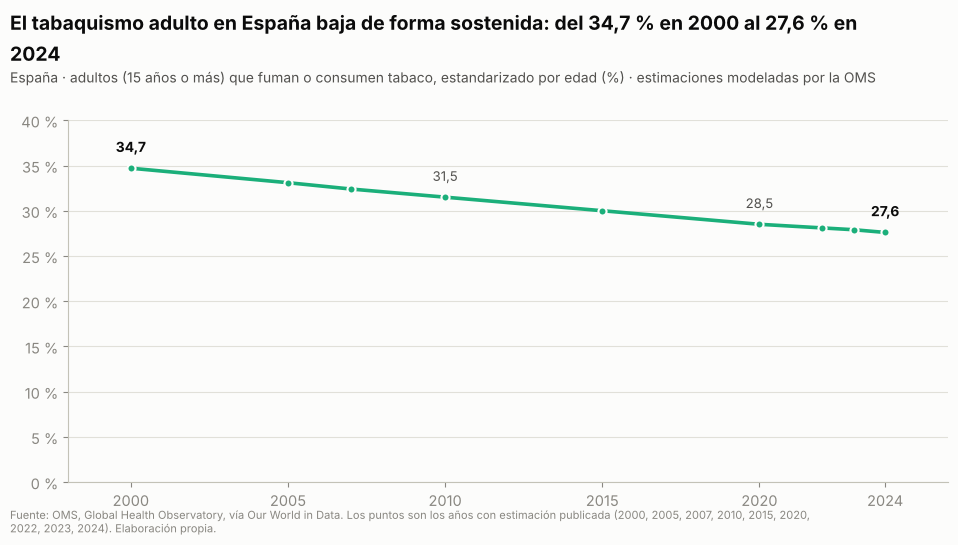

In [5]:
esp_t = tab[tab.Entity == "Spain"].set_index("Year").Tabaquismo
assert esp_t.is_monotonic_decreasing, "el título dice que baja de forma sostenida"

fig, ax = plt.subplots(figsize=(10, 5.4))
fig.subplots_adjust(top=0.78, bottom=0.11, left=0.07, right=0.95)
cabecera(fig, f"El tabaquismo adulto en España baja de forma sostenida: del {fmt(esp_t[2000])} % "
              f"en 2000 al {fmt(esp_t[2024])} % en 2024",
         "España · adultos (15 años o más) que fuman o consumen tabaco, estandarizado por edad (%) · "
         "estimaciones modeladas por la OMS", ancho=88)
ax.plot(esp_t.index, esp_t.values, color=AQUA, lw=2.6)
ax.scatter(esp_t.index, esp_t.values, s=34, color=AQUA, edgecolor=SUPERFICIE, linewidth=1.5, zorder=4)
for y in (2000, 2010, 2020, 2024):
    extremo = y in (2000, 2024)
    ax.text(y, esp_t[y] + 1.8, fmt(esp_t[y]), ha="center", fontsize=10 if extremo else 9.5,
            color=TINTA if extremo else TINTA2, fontweight="bold" if extremo else "normal")
ax.set_ylim(0, 40)
ax.set_xlim(1998, 2026)
ax.set_xticks([2000, 2005, 2010, 2015, 2020, 2024])
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
pie(fig, "Fuente: OMS, Global Health Observatory, vía Our World in Data. Los puntos son los años con estimación "
         "publicada (2000, 2005, 2007, 2010, 2015, 2020, 2022, 2023, 2024). Elaboración propia.")
guardar(fig, "01_tabaquismo_espana_2000_2024")
plt.show()

La figura muestra una sola línea con las estimaciones de la OMS del porcentaje de adultos que consumen tabaco en España, de 2000 a 2024. Se rotulan el primer y el último valor y dos intermedios.

El porcentaje baja en cada estimación disponible, del 34.7% al 27.6%, unos 7.1 punotos o un 20% menos. El ritmo es casi constante (unos 0.3 puntos por año entre 2000 y 2020) y se suaviza algo después de 28.5% en 2020 a 27.6% en 2024.

El descenso coincide con décadas de políticas de control del tabaco, pero estos datos no permiten atribuirlo a ninguna medida concreta. Además, el 27.6% sigue siendo más de uno de cada cuatro adultos.

### **2. ¿Está España mejorando al mismo ritmo que Europa?**

**Pregunta:** ¿cómo se sitúa España frente a Francia, Reino Unido, Italia, Grecia y Noruega?

La comparación europea es contexto.

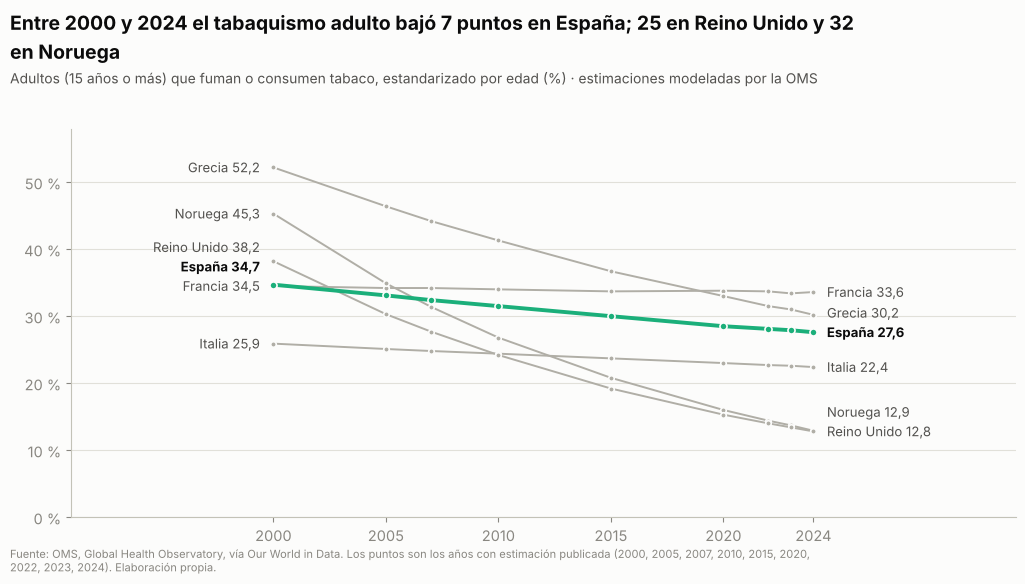

In [6]:
orden = ["France", "Greece", "Italy", "Norway", "United Kingdom", "Spain"]
_p = tab.pivot(index="Entity", columns="Year", values="Tabaquismo")
assert [round(_p.loc[e, 2000] - _p.loc[e, 2024]) for e in ("Spain", "United Kingdom", "Norway")] == [7, 25, 32]

fig, ax = plt.subplots(figsize=(10.5, 5.8))
fig.subplots_adjust(top=0.78, bottom=0.11, left=0.07, right=0.97)
cabecera(fig, "Entre 2000 y 2024 el tabaquismo adulto bajó 7 puntos en España; "
              "25 en Reino Unido y 32 en Noruega",
         "Adultos (15 años o más) que fuman o consumen tabaco, estandarizado por edad (%) · estimaciones modeladas por la OMS",
         ancho=88)

ini, fin = [], []
for e in orden:
    g = tab[tab.Entity == e]
    es_esp = e == "Spain"
    ax.plot(g.Year, g.Tabaquismo, color=AQUA if es_esp else GRIS_CONTEXTO,
            lw=2.8 if es_esp else 1.4, zorder=3 if es_esp else 2)
    ax.scatter(g.Year, g.Tabaquismo, s=26 if es_esp else 16,
               color=AQUA if es_esp else GRIS_CONTEXTO, edgecolor=SUPERFICIE,
               linewidth=1.2, zorder=4)
    peso = "bold" if es_esp else "normal"
    col_t = TINTA if es_esp else TINTA2
    ini.append(dict(x=2000, y=g.Tabaquismo.iloc[0], texto=f"{ES[e]} {fmt(g.Tabaquismo.iloc[0])}",
                    color=col_t, peso=peso))
    fin.append(dict(x=2024, y=g.Tabaquismo.iloc[-1], texto=f"{ES[e]} {fmt(g.Tabaquismo.iloc[-1])}",
                    color=col_t, peso=peso))
ax.set_ylim(0, 58)
gap = 0.05 * 58
etiquetas_finales(ax, ini, gap=gap, x_pad=-0.6, ha="right")
etiquetas_finales(ax, fin, gap=gap, x_pad=0.6, ha="left")
ax.set_xlim(1991, 2033)
ax.set_xticks([2000, 2005, 2010, 2015, 2020, 2024])
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
pie(fig, "Fuente: OMS, Global Health Observatory, vía Our World in Data. Los puntos son los años con estimación "
         "publicada (2000, 2005, 2007, 2010, 2015, 2020, 2022, 2023, 2024). Elaboración propia.")
guardar(fig, "02_tabaquismo_europa_2000_2024")
plt.show()

La figura 2 dibuja las estimaciones de la OMS para seís países entre 2000 y 2024, con España en verde y los demás en gris de contexto.

España baja 7.1 puntos, frenta a 32.4 de Noruega, 25.4 del Reino Unido y 22 de Grecia. Italia y Francia bajan menos. El resultaod es que España, cuarta de seis en 2000, pasa a ser tercera en 2024 (27.6%), por debajo de Francia (33.6%) y Grecia (30.2%) y muy por encima del Reino Unido (12.8%) y Noruega (12.9%). En el conjunto de la UE-27, según el mismo archivo ampliado a todos los países, España ocupa el puesto 13 de 27 por prevalencia en 2024 (la mediana es 26.1%) y su descenso de 7.1 puntos es algo menor que el de la mediana (8 puntos).

In [7]:
piv = tab.pivot(index="Entity", columns="Year", values="Tabaquismo")
cambio_tab = pd.DataFrame({"2000 (%)": piv[2000], "2024 (%)": piv[2024],
                           "cambio (puntos)": piv[2024] - piv[2000]})
cambio_tab.index = [ES[e] for e in cambio_tab.index]
display(cambio_tab.round(1).sort_values("cambio (puntos)"))

,2000 (%),2024 (%),cambio (puntos)
Noruega,45.3,12.9,-32.4
Reino Unido,38.2,12.8,-25.4
Grecia,52.2,30.2,-22.0
España,34.7,27.6,-7.1
Italia,25.9,22.4,-3.5
Francia,34.5,33.6,-0.9


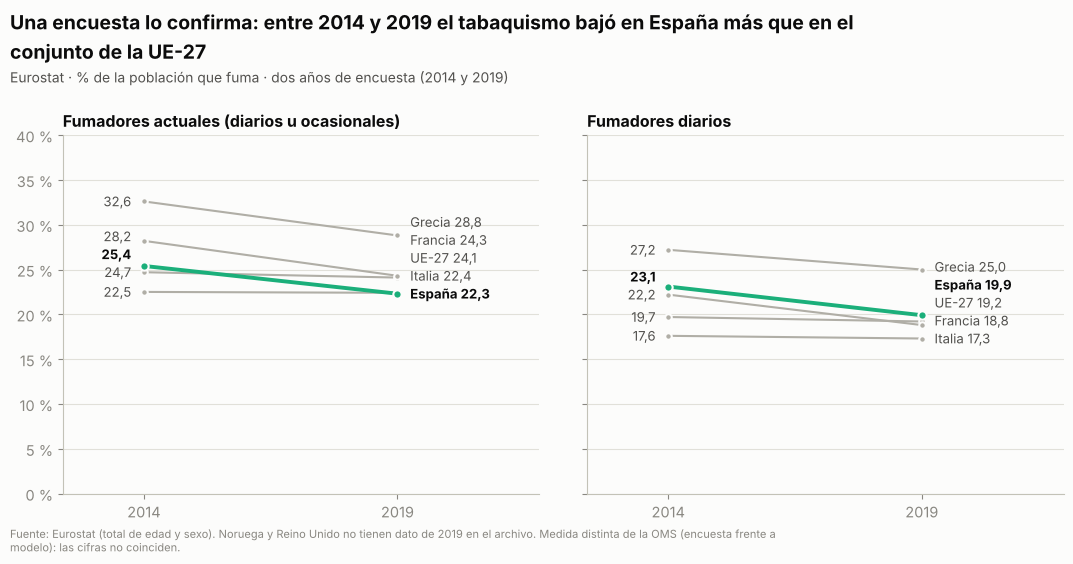

In [8]:
EU27 = "European Union - 27 countries (from 2020)"
NOMBRES_EU = {"Spain": "España", "France": "Francia", "Italy": "Italia", "Greece": "Grecia", EU27: "UE-27"}
orden_eu = [EU27, "Italy", "France", "Greece", "Spain"]

def eur_(df, pais, yr):
    return float(df[(df["Geographic region"] == pais) & (df.Time == yr)].Value.iloc[0])


def dif(df, p):
    return eur_(df, p, 2019) - eur_(df, p, 2014)


assert dif(eu_c, "Spain") < dif(eu_c, EU27) and dif(eu_d, "Spain") < dif(eu_d, EU27)

fig, axes = plt.subplots(1, 2, figsize=(11, 5.6), sharey=True)
fig.subplots_adjust(top=0.76, bottom=0.12, left=0.06, right=0.97, wspace=0.10)
cabecera(fig, "Una encuesta lo confirma: entre 2014 y 2019 el tabaquismo bajó en España más que "
              "en el conjunto de la UE-27",
         "Eurostat · % de la población que fuma · dos años de encuesta (2014 y 2019)", ancho=88)
for ax, (df, titulo) in zip(axes, [(eu_c, "Fumadores actuales (diarios u ocasionales)"),
                                   (eu_d, "Fumadores diarios")]):
    ini, fin = [], []
    for p in orden_eu:
        a, b = eur_(df, p, 2014), eur_(df, p, 2019)
        es_esp = p == "Spain"
        c = AQUA if es_esp else GRIS_CONTEXTO
        ax.plot([2014, 2019], [a, b], color=c, lw=2.8 if es_esp else 1.5, zorder=3 if es_esp else 2)
        ax.scatter([2014, 2019], [a, b], s=36 if es_esp else 22, color=c, edgecolor=SUPERFICIE,
                   linewidth=1.5, zorder=4)
        col_t, peso = (TINTA, "bold") if es_esp else (TINTA2, "normal")
        ini.append(dict(x=2014, y=a, texto=fmt(a), color=col_t, peso=peso))
        fin.append(dict(x=2019, y=b, texto=f"{NOMBRES_EU[p]} {fmt(b)}", color=col_t, peso=peso))
    etiquetas_finales(ax, ini, gap=0.05 * 40, x_pad=-0.25, ha="right")
    etiquetas_finales(ax, fin, gap=0.05 * 40, x_pad=0.25, ha="left")
    ax.set_ylim(0, 40)
    ax.set_xlim(2012.4, 2021.8)
    ax.set_xticks([2014, 2019])
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
    ax.set_title(titulo, loc="left", fontweight="bold")
pie(fig, "Fuente: Eurostat (total de edad y sexo). Noruega y Reino Unido no tienen dato de 2019 en el archivo. "
         "Medida distinta de la OMS (encuesta frente a modelo): las cifras no coinciden.")
guardar(fig, "03_eurostat_2014_2019")
plt.show()

Esta figura usa un gráfico de pendiente con la encuesta de Eurostat, que solo tiene dos años (2014 y 2019), en dos paneles: fumadores actuales (pueden ser diarios u ocasionales) y fumadores diarios.

Entre 2014 y 2019 los fumadores actuales de España pasan del 25.4% al 22.3% y los diarios del 23.1% al 19.9% mientras que en el conjunto de la UE-27 apenas cambian (24.7% a 24.1% y 19.7% a 19.2%). Francia baja aún más que España en esos cinco años, lo que contrasta con su descenso casi nulo en el modelo de la OMS.

In [9]:
mundo = mundo.copy()
mundo.columns = ["Entity", "Code", "Year", "Tabaquismo"]
UE27 = ["Austria", "Belgium", "Bulgaria", "Croatia", "Cyprus", "Czechia", "Denmark", "Estonia", "Finland",
        "France", "Germany", "Greece", "Hungary", "Ireland", "Italy", "Latvia", "Lithuania", "Luxembourg",
        "Malta", "Netherlands", "Poland", "Portugal", "Romania", "Slovakia", "Slovenia", "Spain", "Sweden"]
ue = mundo[mundo.Entity.isin(UE27)].pivot(index="Entity", columns="Year", values="Tabaquismo")
assert len(ue) == 27, "faltan países de la UE-27 en el archivo"
ue["cambio"] = ue[2024] - ue[2000]
puesto = int(ue[2024].rank(ascending=False)["Spain"])
print("UE-27 (OMS, estimaciones modeladas, adultos):")
print(f"  2024: España {fmt(ue.loc['Spain', 2024])} %, mediana UE-27 {fmt(ue[2024].median())} %; "
      f"puesto {puesto} de 27 (1 = más tabaquismo).")
print(f"  Cambio 2000–2024: España {fmt(ue.loc['Spain', 'cambio'])} puntos; mediana UE-27 {fmt(ue['cambio'].median())}; "
      f"{int((ue['cambio'] < ue.loc['Spain', 'cambio']).sum())} países bajaron más que España.")

UE-27 (OMS, estimaciones modeladas, adultos):
  2024: España 27,6 %, mediana UE-27 26,1 %; puesto 13 de 27 (1 = más tabaquismo).
  Cambio 2000–2024: España -7,1 puntos; mediana UE-27 -8,0; 16 países bajaron más que España.



Aunque algunos países europeos han logrado reducciones mucho mayores, España progresa. La comparación europea sirve como contexto y lo relevante es que España baja.

### **3. ¿Qué ha pasado con el cáncer de pulmón?**

**Pregunta:** si el tabaquismo baja, ¿baja también la mortalidad por cáncer de pulmón, y lo hace igual en hombres y en mujeres?

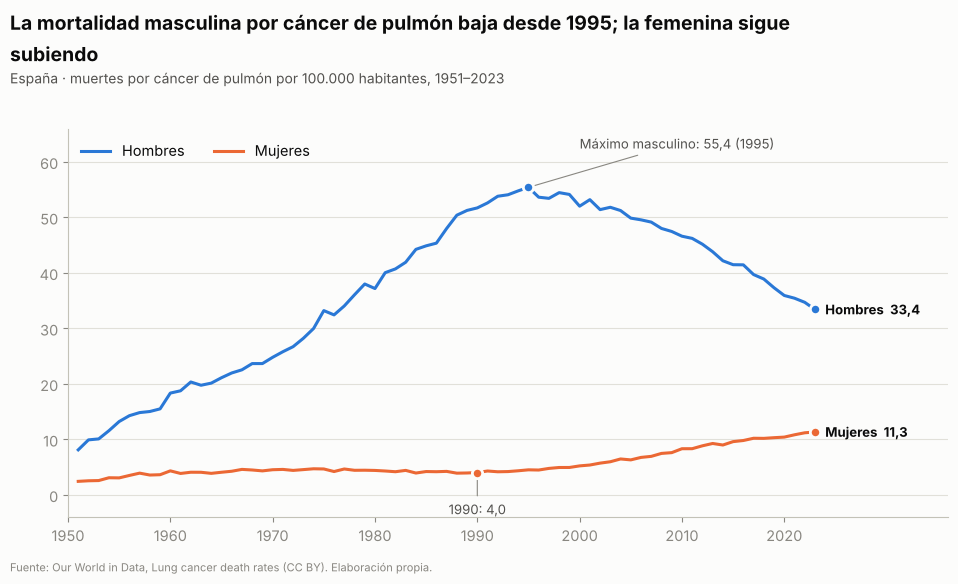

In [10]:
esp = mort[mort.Entity == "Spain"].set_index("Year")
a_max, u = int(esp.Men.idxmax()), int(esp.index.max())

fig, ax = plt.subplots(figsize=(10, 5.8))
fig.subplots_adjust(top=0.78, bottom=0.11, left=0.07, right=0.95)
cabecera(fig, f"La mortalidad masculina por cáncer de pulmón baja desde {a_max}; "
              "la femenina sigue subiendo",
         "España · muertes por cáncer de pulmón por 100.000 habitantes, 1951–2023")

ax.plot(esp.index, esp.Men, color=AZUL, lw=2.2, label="Hombres")
ax.plot(esp.index, esp.Women, color=NARANJA, lw=2.2, label="Mujeres")
for col, c in [("Men", AZUL), ("Women", NARANJA)]:
    ax.scatter([u], [esp[col][u]], s=55, color=c, edgecolor=SUPERFICIE, linewidth=2, zorder=5)
ax.scatter([a_max], [esp.Men[a_max]], s=55, color=AZUL, edgecolor=SUPERFICIE, linewidth=2, zorder=5)
ax.scatter([1990], [esp.Women[1990]], s=55, color=NARANJA, edgecolor=SUPERFICIE, linewidth=2, zorder=5)

ax.annotate(f"Máximo masculino: {fmt(esp.Men[a_max])} ({a_max})",
            xy=(a_max, esp.Men[a_max]), xytext=(a_max + 5, esp.Men[a_max] + 7),
            fontsize=9.5, color=TINTA2, ha="left",
            arrowprops=dict(arrowstyle="-", color=APAGADO, lw=0.8))
ax.annotate(f"1990: {fmt(esp.Women[1990])}", xy=(1990, esp.Women[1990]),
            xytext=(1990, esp.Women[1990] - 7.5), fontsize=9.5, color=TINTA2, ha="center",
            arrowprops=dict(arrowstyle="-", color=APAGADO, lw=0.8))
ax.text(u + 1, esp.Men[u], f"Hombres  {fmt(esp.Men[u])}", va="center", fontsize=9.5,
        color=TINTA, fontweight="bold")
ax.text(u + 1, esp.Women[u], f"Mujeres  {fmt(esp.Women[u])}", va="center", fontsize=9.5,
        color=TINTA, fontweight="bold")

ax.set_xlim(1950, 2036)
ax.set_ylim(-4, 66)
ax.set_xticks(range(1950, 2021, 10))
ax.legend(loc="upper left", ncol=2)
pie(fig, "Fuente: Our World in Data, Lung cancer death rates (CC BY). Elaboración propia.")
guardar(fig, "04_mortalidad_espana_por_sexo")
plt.show()

Con el consumo descrito, esta figura pasa al otro extremo de la cadena: la mortalidad por cáncer de pulmón en España. El grafíco muestra dos líneas, azul para los hombres y naranaja para las mujeres, que cubre de 1951 a 2023 y expresa la tasa en muertes por 100,000 habitantes de cada sexo. Se marcan con un pounto el máximo masculino (1995), el valor femenino de 1990 y los últimos valores de ambas series. El eje vertical es único y comparte escala para ambos sexos, de modo que la diferencia de altura entre las líneas es una diferencia real de magnitud.

Las dos curvas tienen formas opuestas. Entre los hombres, la tasa sube de forma casi continua de 8.1 en 1951 a un máximo de 55.4 en 1995 y desde ahi empieza a bajar. Baja de un 55.4% en 1995 a 33.4% en 2023, lo que equivale a una bajada de un 40%. Entre las mujeres la tasa parte de niveles mucho más bajos (2.4 en 1951, 4 en 1990) y crece sin interrupción desde 1990 hasta un 11.3 en 2023, que es su valor más alto. En resumen, la tasa femenina se ha multiplicado por 2.8 dese 1990, mientras que la masculina ha retrocedido casi hasta donde estaba hace medio siglo.

Hay una cautela importante al comparar las magnitudes y es que la caída masculina en tasa (22 puntos desde 1995( es tres veces mayor que el aumento femenino (7.3 puntos desde 1990), pero esas tasas no pueden sumarse sin ponderarlas por el tamaño de cada población, por lo que el gráfico no permite afirmar cuál es el efecto neto sobre el número total de muertes. Lo que si se muestra con claridad es la dirección de cada tendencia. La interpretación habitual de estas formas es el retardo entre fumar y enfermar.

La reducción del tabaquismo no se refleja de la misma manera en toda la población. Los hombres muestran una mejora clara en la mortalidad, en cambio las mujeres no.

### **4. Mortalidad: Hombres y Mujeres**

**Pregunta:** ¿cuánto se parecen hoy las tasas de mortalidad de mujeres y hombres, y por qué se han acercado?

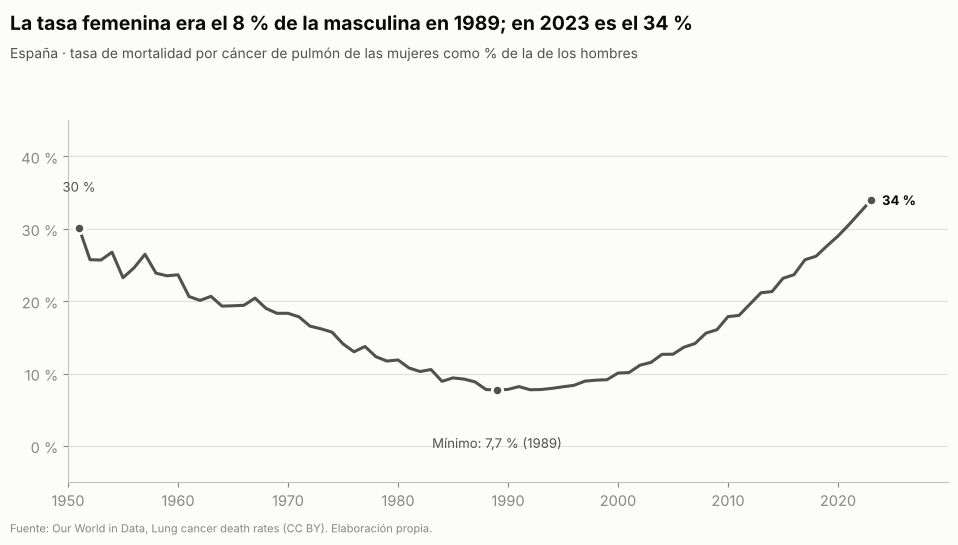

In [11]:
ratio = (esp.Women / esp.Men) * 100
y_min = int(ratio.idxmin())

fig, ax = plt.subplots(figsize=(10, 5.4))
fig.subplots_adjust(top=0.78, bottom=0.11, left=0.07, right=0.95)
cabecera(fig, f"La tasa femenina era el {fmt(ratio.min(), 0)} % de la masculina en {y_min}; "
              f"en 2023 es el {fmt(ratio[u], 0)} %",
         "España · tasa de mortalidad por cáncer de pulmón de las mujeres como % de la de los hombres")

ax.plot(ratio.index, ratio.values, color=TINTA2, lw=2.2)
for y in (1951, y_min, u):
    ax.scatter([y], [ratio[y]], s=55, color=TINTA2, edgecolor=SUPERFICIE, linewidth=2, zorder=5)
ax.annotate(f"{fmt(ratio[1951], 0)} %", xy=(1951, ratio[1951]), xytext=(1951, ratio[1951] + 5),
            fontsize=9.5, color=TINTA2, ha="center")
ax.annotate(f"Mínimo: {fmt(ratio[y_min], 1)} % ({y_min})", xy=(y_min, ratio[y_min]),
            xytext=(y_min, ratio[y_min] - 8), fontsize=9.5, color=TINTA2, ha="center")
ax.annotate(f"{fmt(ratio[u], 0)} %", xy=(u, ratio[u]), xytext=(u + 1, ratio[u]),
            fontsize=9.5, color=TINTA, fontweight="bold", va="center")
ax.set_xlim(1950, 2030)
ax.set_ylim(-5, 45)
ax.set_xticks(range(1950, 2021, 10))
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
pie(fig, "Fuente: Our World in Data, Lung cancer death rates (CC BY). Elaboración propia.")
guardar(fig, "05_brecha_mortalidad_sexos")
plt.show()

La figura 5 resume en una sola curva lo que la figura 4 muestra con dos. Representa, para cada año entre 1951 y 2023, la tasa de mortalidad de las mujeres expresada como porcentaje de la de los hombres: un valor del 30% significa que, por cada 100 muertes masculinas por 100,000 habitantes, hay 30 femeninas en la misma proporción de población. La linea esta dibujada en gris ya que no es un color que pertenece a ningún sexo ni producto. Se rotulan tres puntos: el inicio de la serie, el mínimo y el último valor. La ventaje de este indicador es que elimina la diferencia de escala entre las dos curvas y deja ver con nitidez cuánto se parecen o se distancian los dos sexos.

La serie describe una U muy marcada. En 1951, la tasa femenina equivale el 30.1% de la masculina. Baja de forma continua hasta el 23.6% en 1960, el 18.3% en 1970 y el 11.9% en 1980, y toca fondo en 1989 con un 7.7% cuando los hombres ya superaban 51 muertes por 100,000 habitantes y las mujeres apenas 4. A partir de ese año la curvsa sube sin interrupción: 10.1% en 2000, 17.9% en 2010, 23.2% en 2015, 29.0% en 2020 y 34.0% en 2023, un valor que supera el de 1951. La diferencia entre la tasa masculina y la femenina pasa de 47.7 muertes por 100,000 habitantes en 1990 a 22.1 en 2023, menos de la mitad.

La brecha se cierra no por qué hubo una mejora entre las mujeres, si no por qué el cociente sube por la combinación de dos movimientos simultáneos. Entre 1989 y 2023 la tasa femenina se multiplica por casi tres y la masculina baja a dos tercios. Ningún movimiento por sí solo habría cerrado tanto la distancia. Si los hombres hubieran bajado sin que las mujeres subieran, el cociente habría llegado a unos 11.9%, y si las mujeres hubieran subido sin que los hombres bajaron, a unos 22.1%.

### **5. ¿Es España una excepción en mortalidad?**

**Pregunta:** ¿siguen otros países europeos las mismas trayectorias?

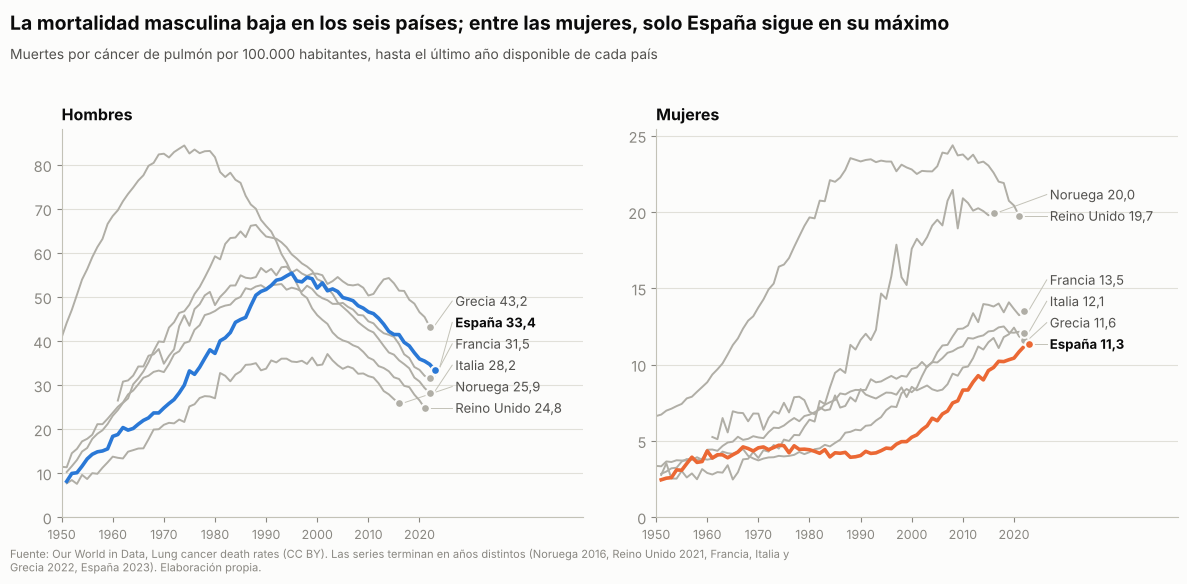

In [12]:
orden = ["France", "Greece", "Italy", "Norway", "United Kingdom", "Spain"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.8))
fig.subplots_adjust(top=0.78, bottom=0.11, left=0.055, right=0.985, wspace=0.14)
cabecera(fig, "La mortalidad masculina baja en los seis países; entre las mujeres, "
              "solo España sigue en su máximo",
         "Muertes por cáncer de pulmón por 100.000 habitantes, hasta el último año disponible de cada país",
         ancho=98)

for ax, (col, titulo, color) in zip(axes, [("Men", "Hombres", AZUL), ("Women", "Mujeres", NARANJA)]):
    etiquetas = []
    for e in orden:
        g = mort[mort.Entity == e]
        es_esp = e == "Spain"
        ax.plot(g.Year, g[col], color=color if es_esp else GRIS_CONTEXTO,
                lw=2.6 if es_esp else 1.4, zorder=3 if es_esp else 2)
        ax.scatter([g.Year.iloc[-1]], [g[col].iloc[-1]], s=40,
                   color=color if es_esp else GRIS_CONTEXTO, edgecolor=SUPERFICIE,
                   linewidth=1.5, zorder=4)
        etiquetas.append(dict(x=g.Year.iloc[-1], y=g[col].iloc[-1],
                              texto=f"{ES[e]} {fmt(g[col].iloc[-1])}",
                              color=TINTA if es_esp else TINTA2,
                              peso="bold" if es_esp else "normal"))
    ax.set_ylim(0, ax.get_ylim()[1])
    etiquetas_con_guia(ax, etiquetas, x_label=2027, gap=0.055 * ax.get_ylim()[1])
    ax.set_xlim(1950, 2052)
    ax.set_xticks(range(1950, 2021, 10))
    ax.tick_params(axis="x", labelsize=9)
    ax.set_title(titulo, loc="left", fontweight="bold")
pie(fig, "Fuente: Our World in Data, Lung cancer death rates (CC BY). Las series terminan en años distintos "
         "(Noruega 2016, Reino Unido 2021, Francia, Italia y Grecia 2022, España 2023). Elaboración propia.")
guardar(fig, "06_mortalidad_comparacion_paises")
plt.show()

La figura sitúa la experiencia española en un contexto comparado. Aquí se repite la mortalidad por cáncer de pulmón en dos paneles, uno para hombres y otor para mujeres, e incluye seis países (España, Francia, Italia, Grecia, Reino Unido y Noruega). España se dibuja en color, siguiendo la convención de sexo del informe, y el resto de países en gris. Cada serie llega hasta el último año disponible de su país, lo que explica que las curvas terminen en puntos distintos del eje horizontal.

En los hombres, la mortalidad baja en los seis países, aunque con intensidades muy diferentes. El Reino Unido, que fue el primero en alcanzar su techo (1974 con 84.4 muertes por 100,000 habitantes), es también el que más ha descendido, un 71%. Le siguen Italia, con un 57% de caída desde su máximo de 1988, España y Francia, que coinciden en un descenso del 40% (España desde 1995 y Francia desde 1993). Noruega, con un máximo de 37.0 en 2002, desciende un 30% y Grecia cuyo máximo de 56.9 es de 1994, es el país que menos ha bajado, un 24%.

En las mujeres, la lectura es muy distinta. Las tasas acutales forman dos grupos: el Reino Unido (máximo de 24.4 en 2008) y Noruega (21.4 en 2008, pero su serie termina en 2016) se sitúan en torno a 20 por 100,000 mientras que los países mediterráneos se mueven entre 11 y 14. Italia llega a 12,5 en 2018, Francia a 14.1 en 2019, Grecia a 12.4 en 2020 y España a 11.3 en 2023.

### **6. ¿Cuánto se ha avanzado desde el máximo?**

**Pregunta:** ¿cuánto ha descendido la tasa de cada país respecto de su propio máximo histórico?

In [13]:
filas = []
for e, g in mort.groupby("Entity"):
    g = g.set_index("Year")
    for sexo, col in [("Hombres", "Men"), ("Mujeres", "Women")]:
        s = g[col]
        ap, ul = int(s.idxmax()), int(s.index.max())
        filas.append(dict(país=ES[e], sexo=sexo, año_máximo=ap, tasa_máxima=s[ap],
                          último_año=ul, tasa_último_año=s[ul],
                          cambio_desde_máximo_pct=(s[ul] / s[ap] - 1) * 100))
resumen = pd.DataFrame(filas)
display(resumen.round(1).sort_values(["sexo", "cambio_desde_máximo_pct"]).reset_index(drop=True))

,país,sexo,año_máximo,tasa_máxima,último_año,tasa_último_año,cambio_desde_máximo_pct
0,Reino Unido,Hombres,1974,84.4,2021,24.8,-70.6
1,Italia,Hombres,1988,66.4,2022,28.2,-57.5
2,Francia,Hombres,1993,52.9,2022,31.5,-40.5
3,España,Hombres,1995,55.4,2023,33.4,-39.7
4,Noruega,Hombres,2002,37.0,2016,25.9,-30.1
5,Grecia,Hombres,1994,56.9,2022,43.2,-24.0
6,Reino Unido,Mujeres,2008,24.4,2021,19.7,-19.0
7,Noruega,Mujeres,2008,21.4,2016,20.0,-6.9
8,Grecia,Mujeres,2020,12.4,2022,11.6,-6.3
9,Francia,Mujeres,2019,14.1,2022,13.5,-4.1


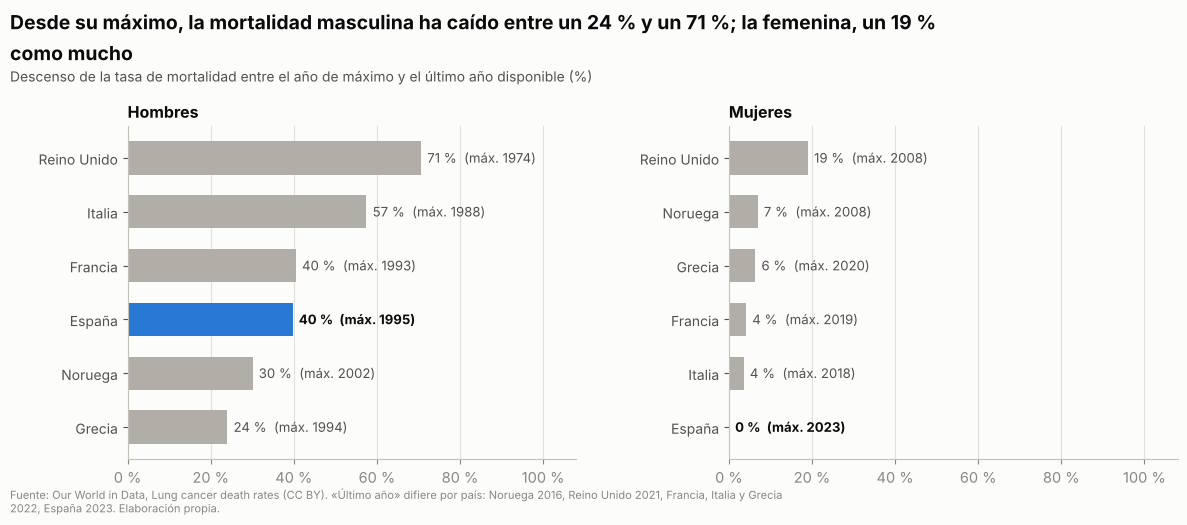

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True)
fig.subplots_adjust(top=0.76, bottom=0.12, left=0.11, right=0.985, wspace=0.34)
h = resumen[resumen.sexo == "Hombres"].cambio_desde_máximo_pct
mj = resumen[resumen.sexo == "Mujeres"].cambio_desde_máximo_pct
cabecera(fig, f"Desde su máximo, la mortalidad masculina ha caído entre un {fmt(-h.max(), 0)} % y un "
              f"{fmt(-h.min(), 0)} %; la femenina, un {fmt(-mj.min(), 0)} % como mucho",
         "Descenso de la tasa de mortalidad entre el año de máximo y el último año disponible (%)",
         ancho=98)

for ax, (sexo, color) in zip(axes, [("Hombres", AZUL), ("Mujeres", NARANJA)]):
    d = resumen[resumen.sexo == sexo].copy()
    d["descenso"] = -d.cambio_desde_máximo_pct
    d = d.sort_values("descenso")
    colores = [color if p == "España" else GRIS_CONTEXTO for p in d["país"]]
    ax.barh(d["país"], d["descenso"], color=colores, height=0.62)
    for _, r in d.iterrows():
        v = abs(r.descenso) if r.descenso > 0 else 0.0     # evita «-0 %»
        txt = f"{fmt(v, 0)} %  (máx. {r.año_máximo})"
        ax.text(v + 1.5, r["país"], txt, va="center", fontsize=9.5,
                color=TINTA if r["país"] == "España" else TINTA2,
                fontweight="bold" if r["país"] == "España" else "normal")
    ax.set_xlim(0, 108)
    ax.set_xticks(range(0, 101, 20))
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_title(sexo, loc="left", fontweight="bold")
    ax.tick_params(axis="y", labelsize=10, colors=TINTA2)
pie(fig, "Fuente: Our World in Data, Lung cancer death rates (CC BY). «Último año» difiere por país: "
         "Noruega 2016, Reino Unido 2021, Francia, Italia y Grecia 2022, España 2023. Elaboración propia.")
guardar(fig, "07_descenso_desde_maximo")
plt.show()

Esta figura condensa la compración en un solo número por país y sexo: cuánto ha descendido o no la tasa desde su propio máximo histórico, representado con barras horizontales.

Ningún país ha reducido su mortalidad femenina más de un 19% desde el máximo (Reino Unido) y los demás apenas se separan del suyo, con descensos del 7% en Noruega, del 6% en Grecia y del 4% en Francia y Italia. España es el único caso en el que la serie alcanza su máximo precisamente en el último año disponible, de modo que su variación desde el máximo es del 0%.

Esta figura y la anterior demuestran que España no es una excepción entre los hombres pero sí lo es por la tendencia femenina, ya que el resto de los países estudiades ha pasado su máximo o lo mantiene estable. Esta diferencia es coherente con la idea de que el retraso en la epidemia de tabaquismo femenino en España se traduce en un retraso equivalente en la mortalidad, pero estos datos no permiten confirmarlo.

Dos cautelas que añadir: 1. Las series terminan en años distintos, por lo que el porcentaje de descenso desde el máximo no se mide sobre el mismo periodo para todos. 2. La fuente de mortalidad no documenta si las tasas están estandarizadas por edad, de manera que las diferencias de nivel entre países deben leerse como orientativas y la comparación de trayectorias es más fiable que la de valores absolutos.

### **7. ¿Quién fuma actualmente en España?**

**Pregunta:** ¿afecta el tabaquismo por igual a hombres y mujeres, y a todos los grupos de edad?

### 7.1 Adultos, por sexo

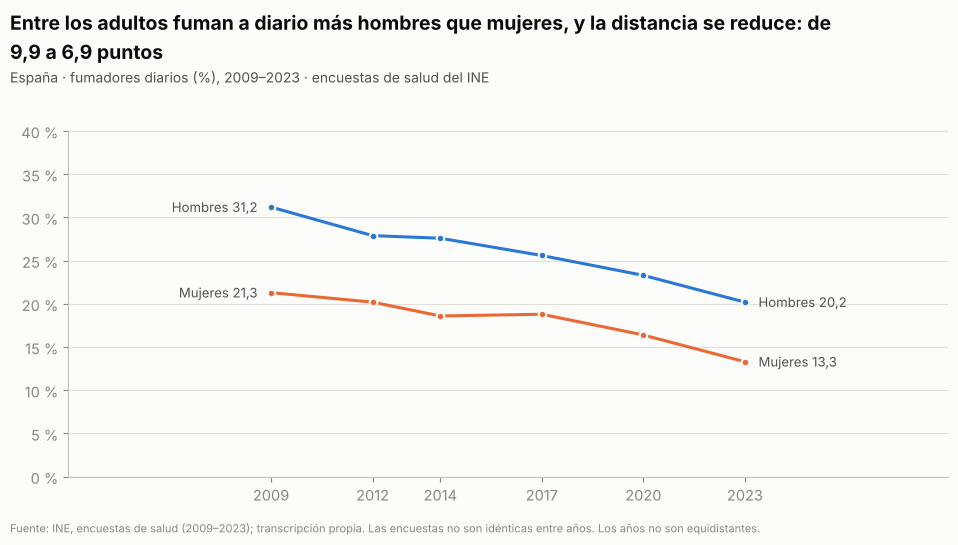

In [15]:
ine = ine_raw.set_index("year")
assert (ine.men > ine.women).all()

fig, ax = plt.subplots(figsize=(10, 5.4))
fig.subplots_adjust(top=0.76, bottom=0.12, left=0.07, right=0.95)
brecha0, brecha1 = ine.men.iloc[0] - ine.women.iloc[0], ine.men.iloc[-1] - ine.women.iloc[-1]
cabecera(fig, f"Entre los adultos fuman a diario más hombres que mujeres, y la distancia se reduce: "
              f"de {fmt(brecha0)} a {fmt(brecha1)} puntos",
         f"España · fumadores diarios (%), {ine.index.min()}–{ine.index.max()} · encuestas de salud del INE", ancho=88)
for col, color, nombre in [("men", AZUL, "Hombres"), ("women", NARANJA, "Mujeres")]:
    ax.plot(ine.index, ine[col], color=color, lw=2.2)
    ax.scatter(ine.index, ine[col], s=30, color=color, edgecolor=SUPERFICIE, linewidth=1.5, zorder=4)
    ax.text(ine.index[0] - 0.4, ine[col].iloc[0], f"{nombre} {fmt(ine[col].iloc[0])}", ha="right", va="center",
            fontsize=9.5, color=TINTA2)
    ax.text(ine.index[-1] + 0.4, ine[col].iloc[-1], f"{nombre} {fmt(ine[col].iloc[-1])}", ha="left", va="center",
            fontsize=9.5, color=TINTA2)
ax.set_ylim(0, 40)
ax.set_xlim(2003, 2029)
ax.set_xticks(list(ine.index))
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
pie(fig, "Fuente: INE, encuestas de salud (2009–2023); transcripción propia. Las encuestas no son idénticas entre años. "
         "Los años no son equidistantes.")
guardar(fig, "08_fumadores_diarios_adultos_por_sexo")
plt.show()

In [16]:
picos = ctx[ctx.measure.str.contains("máximo")][["dataset", "year", "population", "measure", "value"]]
picos = picos.rename(columns={"dataset": "encuesta", "year": "año", "population": "grupo",
                              "measure": "medida", "value": "%"})
print("Grupos de edad con mayor consumo diario (INE, 2023):")
display(picos)

Grupos de edad con mayor consumo diario (INE, 2023):


,encuesta,año,grupo,medida,%
6,INE_ESdE,2023,Hombres 25-34 años,fumadores diarios (máximo por edad entre hombres),26.7
7,INE_ESdE,2023,Mujeres 45-54 años,fumadoras diarias (máximo por edad entre mujeres),19.4


### 7.2 Jovenes de 14 a 18 años, por sexo

In [17]:
est = est_raw.set_index("year")

#Controles de coherencia lógica: quien fuma a diario también fumó en los últimos 30 días, etc.
for g in ["total", "boys", "girls"]:
    assert (est[f"d30_{g}"] >= est[f"daily_{g}"]).all(), f"diario > 30 días ({g})"
    assert (est[f"ever_{g}"] >= est[f"d30_{g}"]).all(), f"alguna vez < 30 días ({g})"
    sub = est.dropna(subset=[f"m12_{g}"])
    assert (sub[f"m12_{g}"] >= sub[f"d30_{g}"]).all(), f"12 meses < 30 días ({g})"
    assert (sub[f"ever_{g}"] >= sub[f"m12_{g}"]).all(), f"alguna vez < 12 meses ({g})"
#El total debe quedar entre chicos y chicas
for ind in ["ever", "d30", "daily"]:
    lo = est[[f"{ind}_boys", f"{ind}_girls"]].min(axis=1)
    hi = est[[f"{ind}_boys", f"{ind}_girls"]].max(axis=1)
    assert ((est[f"{ind}_total"] >= lo) & (est[f"{ind}_total"] <= hi)).all(), f"total fuera de rango ({ind})"
print(f"Controles superados: {len(est)} oleadas ({est.index.min()}–{est.index.max()}), "
      "series coherentes (alguna vez ≥ 12 meses ≥ 30 días ≥ diario; total entre chicos y chicas).")

Controles superados: 14 oleadas (1996–2023), series coherentes (alguna vez ≥ 12 meses ≥ 30 días ≥ diario; total entre chicos y chicas).


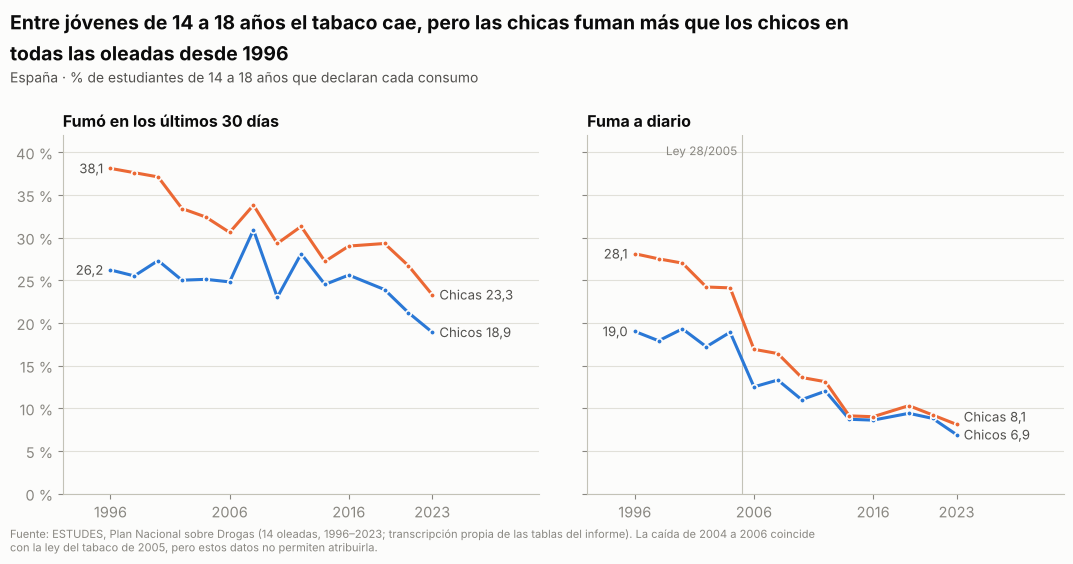

In [18]:
assert (est.d30_girls > est.d30_boys).all() and (est.daily_girls > est.daily_boys).all()

fig, axes = plt.subplots(1, 2, figsize=(11, 5.6), sharey=True)
fig.subplots_adjust(top=0.76, bottom=0.12, left=0.06, right=0.97, wspace=0.10)
cabecera(fig, "Entre jóvenes de 14 a 18 años el tabaco cae, pero las chicas fuman más "
              "que los chicos en todas las oleadas desde 1996",
         "España · % de estudiantes de 14 a 18 años que declaran cada consumo", ancho=88)

for ax, (col, titulo) in zip(axes, [("d30", "Fumó en los últimos 30 días"), ("daily", "Fuma a diario")]):
    fin, ini = [], []
    for sexo, color, nombre in [("boys", AZUL, "Chicos"), ("girls", NARANJA, "Chicas")]:
        y = est[f"{col}_{sexo}"]
        ax.plot(est.index, y, color=color, lw=2.2)
        ax.scatter(est.index, y, s=16, color=color, edgecolor=SUPERFICIE, linewidth=1.2, zorder=4)
        ini.append(dict(x=est.index[0], y=y.iloc[0], texto=fmt(y.iloc[0]), color=TINTA2))
        fin.append(dict(x=est.index[-1], y=y.iloc[-1], texto=f"{nombre} {fmt(y.iloc[-1])}", color=TINTA2))
    etiquetas_finales(ax, ini, gap=0.05 * 42, x_pad=-0.6, ha="right")
    etiquetas_finales(ax, fin, gap=0.05 * 42, x_pad=0.6, ha="left")
    ax.set_ylim(0, 42)
    ax.set_xlim(1992, 2032)
    ax.set_xticks([1996, 2006, 2016, 2023])
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
    ax.set_title(titulo, loc="left", fontweight="bold")
axes[1].axvline(2005, color=EJE, lw=0.8, zorder=1)
axes[1].text(2004.6, 41, "Ley 28/2005", ha="right", va="top", fontsize=8.5, color=APAGADO)
pie(fig, "Fuente: ESTUDES, Plan Nacional sobre Drogas (14 oleadas, 1996–2023; transcripción propia de las tablas del informe). "
         "La caída de 2004 a 2006 coincide con la ley del tabaco de 2005, pero estos datos no permiten atribuirla.")
guardar(fig, "09_tabaco_estudiantes_por_sexo")
plt.show()

Las figuras 7.1 y 7.2 responden a una pregunta que las series nacionales no pueden contestar y es quién fuma. Los archivos de Eurostat solo incluyen el total de la población, sin desglose por sexo ni edad, por lo que el análisis por grupos se apoya en dos fuentes españolas. La figura 7.1 dibjua el porcentaje de adultos que fuma a diario, separado por sexo, a partir de seis encuestas del INE realizadas entre 2009 y 2023. La figura 7.2 muestra el consumo de tabaco entre estudiantes de 14 a 18 años según el sexo, con datos de las 14 oleadas de la encuesta ESTUDES entre 1996 y 2023, en dos paneles: haber fumado en los últimos 30 días y fumar a diario.

En la población adulta, fuman a diario más hombres que mujeres en todas las encuestas, pero ambas líneas descienden. Los hombres pasan del 31.2% en 2009 al 20.2% en 2023, una caída de 11 puntos, y las mujeres del 21.3% al 13.3%, una caída de 8 puntos. Como los hombres parten de un nivel más alto y bajan algo más, la distancia entre ambos sexos se reduce de 9.9 puntos a 6.9.

El INE aporta además un matiz sobre la edad: en 2023 los consumos diarios más altos se observan en los hombres de 25 a 34 años (26.7%) y en las mujeres de 45 a 54 años (19.4%), lo que indica que el tabaquismo se concentra en grupos de edad distintos según el sexo.

En los jovenes, el tabaco también desciende, pero a ritmo diferente. El consumo diario pasa del 23.7% en 1996 al 7.5% en 2023, con una caída brusca entre 2004 (21.5%) y 2006 (14.8%) que coincide en el tiempo con la ley del tabaco de 2005, aunque estos datos no permiten atribuirle ese efecto. El consumo en los últimos 30 días desciende bastante menos, del 32.5% al 21% y entre 2006 y 2019 se mueve en una banda de entre el 26% y el 32%. La diferencia entre ambas curvas muestra que hay menos fumadores diarios, pero el consumo ocasional persiste, lo que sugiere que una parte de los jovenes sigue en contacto con el tabaco aunque no sea una rutina diaria.

El rasgo mas claro de esta figura es la diferencia por sexo. Las chicas superan a los chicos en todas las oleadas. En el consumo diario, la distancia era de 9.1 puntos en 1996 y se ha reducido a 1.2 en 2023. En cuanto al último mes, en 2023 fumaron el 23.3% de las chicas y el 18.9% de los chicos.

La lectura conjunta de ambas figuras muestra que el patrón por sexo se invierte con la edad: entre adultos fumán más los hombres y entre jovenes fuman más las chicas.

Los niveles de ambas encuestas no son comparables entre sí, porque la población, la edad y la definición de consumo son disntitas, de modo que solo es legible el sentido de la diferencia y no su magnitud. Además, ESTUDES se realiza en centros educativos y no incluye a los jóvenes que han abandonado los estudios, por lo que sus cifras pueden no reflejar a toda la población de esas edades.

### **8. ¿Está apareciendo una nueva generación de consumidores de nicotina?**

**Pregunta:** ¿ha sustituido el vapeo al tabaco entre los adolescentes, o aparecen nuevas formas de consuma mientras el cigarrillo tradicional disminuye?

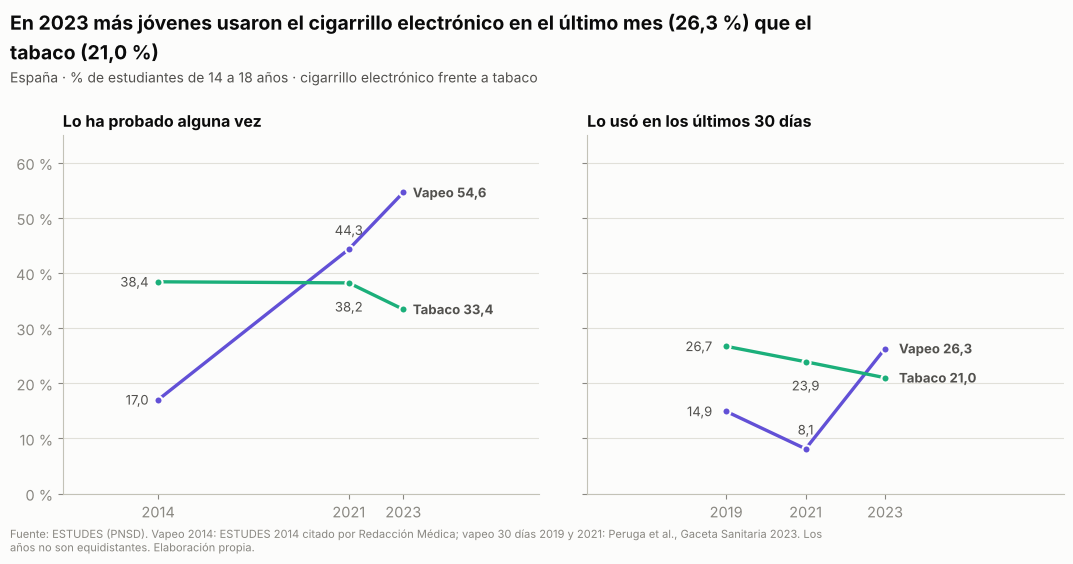

In [19]:
vap_ever = vap[vap.indicator == "ever"].set_index("year").total
vap_30 = vap[vap.indicator == "last30d"].set_index("year").total
tab_ever = est.ever_total.loc[vap_ever.index]
tab_30 = est.d30_total.loc[vap_30.index]
assert vap_30[2023] > tab_30[2023] and vap_ever[2023] > tab_ever[2023]

fig, axes = plt.subplots(1, 2, figsize=(11, 5.6), sharey=True)
fig.subplots_adjust(top=0.76, bottom=0.12, left=0.06, right=0.97, wspace=0.10)
cabecera(fig, f"En 2023 más jóvenes usaron el cigarrillo electrónico en el último mes "
              f"({fmt(vap_30[2023])} %) que el tabaco ({fmt(tab_30[2023])} %)",
         "España · % de estudiantes de 14 a 18 años · cigarrillo electrónico frente a tabaco", ancho=88)

paneles = [("Lo ha probado alguna vez", vap_ever, tab_ever),
           ("Lo usó en los últimos 30 días", vap_30, tab_30)]
for ax, (titulo, v, t) in zip(axes, paneles):
    fin, ini = [], []
    for serie, color, nombre in [(v, VIOLETA, "Vapeo"), (t, AQUA, "Tabaco")]:
        ax.plot(serie.index, serie.values, color=color, lw=2.4)
        ax.scatter(serie.index, serie.values, s=34, color=color, edgecolor=SUPERFICIE, linewidth=1.5, zorder=4)
        ini.append(dict(x=serie.index[0], y=serie.iloc[0], texto=fmt(serie.iloc[0]), color=TINTA2))
        fin.append(dict(x=serie.index[-1], y=serie.iloc[-1], texto=f"{nombre} {fmt(serie.iloc[-1])}",
                        color=TINTA2, peso="bold"))
        if len(serie) == 3:
            m = serie.iloc[1]
            ax.text(serie.index[1], m + (2.6 if color == VIOLETA else -5.2), fmt(m), ha="center", fontsize=9.5, color=TINTA2)
    etiquetas_finales(ax, ini, gap=0.05 * 65, x_pad=-0.35, ha="right")
    etiquetas_finales(ax, fin, gap=0.05 * 65, x_pad=0.35, ha="left")
    ax.set_ylim(0, 65)
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v_, _: f"{v_:.0f} %"))
    ax.set_title(titulo, loc="left", fontweight="bold")
axes[0].set_xlim(2010.5, 2028)
axes[0].set_xticks([2014, 2021, 2023])
axes[1].set_xlim(2015.5, 2027.5)
axes[1].set_xticks([2019, 2021, 2023])
pie(fig, "Fuente: ESTUDES (PNSD). Vapeo 2014: ESTUDES 2014 citado por Redacción Médica; vapeo 30 días 2019 y 2021: Peruga et al., "
         "Gaceta Sanitaria 2023. Los años no son equidistantes. Elaboración propia.")
guardar(fig, "10_vapeo_frente_a_tabaco_estudiantes")
plt.show()

La figura 10 intenta responder a la siguiente pregunta: si, mientras el tabaco tradicional retrocede, aparece una nueva generación de consumidores de nicotina. El gráfico utiliza dos paneles con estudiantes de 14 a 18 años y compara, en cada uno, el cigarrillo electrónico (violeta) con el tabaco (aguamarina). El panel izquierdo mide el porcentaje que lo ha probado alguna vez en 2014, 2021 y 2023, mientras que el derecho mide quién lo ha usado en los últimos 30 dias en 2019, 2021 y 2023. Los años disponibles no son equidistantes. La tabla a continuación complementaria desglosa las cifras por sexo de 2023.

En el indicador de "alguna vez" el vapeop sube del 17% en 2014 al 44.3% en 2021 y al 54.6% en 2023, mientras que el tabaco baja del 38.4% al 33.4% en el mismo periodo. En 2023, hay más estudiantes que han probado el cigarrillo electrónico que el tabaco, y entre los de 18 años el 66% ya lo ha probado. En el indicador de uso reciente, el cambio es igualmente claro: en 2019 el vapeo (14.9%) era poco más de la mitad del tabaco (26.7%), pero en 2023 lo supera, con un 26.3% frente a un 21%. El vapeo pasa de minoritario a más habitual que el tradicional tanto en la prueba como en el uso del último mes.

El desglose por sexo de 2023 repite el patrón observado con el tabaco. Las chicas usan más el cigarrillo electrónico que los chicos, con un 27.9% frente a un 24.7% en el último mes y un 56.8% frente a un 52.5% en el indicador de alguna vez.

Para los adultos, el uso sigue siendo minoritario, aunque creciente. Según el INE, el uso diario u ocasional del cigarrillo electrónico pasa del 0.94% en 2020 al 1.60% en 2023 en la población de 15 o más años, y llega al 3.5% entre los 15 y los 34 años. En la encuesta EDADES, el porcentaje de personas de 15 a 64 años que lo han probado alguna vez pasa del 10.5% en 2020 al 12.1% en 2022 y al 19% en 2024.

Lo que podemos concluir de esta sección es que, aunque los cigarrillos tradicionales disminuyen, aparecen nuevas formas de consumo de nicotina, sobre todo entre los más jóvenes. El dato de 2021 en el último mes (8.1%) es inferior al de 2019, y esa caída coincide con la pandemia, aunque estos datos no permiten explicarla. Las cifras de 2014, 2019 y 2021 proceden de fuentes distintas a las de 2023 y su definición puede no ser idéntica. Además, "alguna vez" incluye un solo uso, que no equivale a un consumo habitual y no es posible saber cuántos estudiantes usan ambos productos.



In [20]:
tabla23 = pd.DataFrame({
    "Tabaco": [est.ever_total[2023], est.ever_boys[2023], est.ever_girls[2023],
               est.d30_total[2023], est.d30_boys[2023], est.d30_girls[2023]],
    "Cigarrillo electrónico": [vap_ever[2023], vap[(vap.indicator == "ever") & (vap.year == 2023)].boys.iloc[0],
                               vap[(vap.indicator == "ever") & (vap.year == 2023)].girls.iloc[0],
                               vap_30[2023], vap[(vap.indicator == "last30d") & (vap.year == 2023)].boys.iloc[0],
                               vap[(vap.indicator == "last30d") & (vap.year == 2023)].girls.iloc[0]],
}, index=pd.MultiIndex.from_product([["Alguna vez", "Últimos 30 días"], ["Total", "Chicos", "Chicas"]]))
print("ESTUDES 2023, estudiantes de 14 a 18 años (%):")
display(tabla23)

ESTUDES 2023, estudiantes de 14 a 18 años (%):


Tabaco  Cigarrillo electrónico
Alguna vez      Total     33.4                    54.6
                Chicos    30.0                    52.5
                Chicas    36.8                    56.8
Últimos 30 días Total     21.0                    26.3
                Chicos    18.9                    24.7
                Chicas    23.3                    27.9

In [21]:
tabla_ctx = ctx[["dataset", "year", "population", "measure", "value"]].rename(
    columns={"dataset": "encuesta", "year": "año", "population": "población", "measure": "medida", "value": "%"})
print("Datos de contexto en adultos: encuestas, edades y definiciones distintas, por lo que no son comparables entre filas.")
display(tabla_ctx)

Datos de contexto en adultos: encuestas, edades y definiciones distintas, por lo que no son comparables entre filas.


,encuesta,año,población,medida,%
0,EDADES,2020,15-64 años,"cigarrillo electrónico, alguna vez en la vida",10.50
1,EDADES,2022,15-64 años,"cigarrillo electrónico, alguna vez en la vida",12.10
2,EDADES,2024,15-64 años,"cigarrillo electrónico, alguna vez en la vida",19.00
3,INE_ESdE,2020,15 y más años,"cigarrillo electrónico, uso diario u ocasional",0.94
4,INE_ESdE,2023,15 y más años,"cigarrillo electrónico, uso diario u ocasional",1.60
5,INE_ESdE,2023,15-34 años,"cigarrillo electrónico, uso diario u ocasional",3.50
6,INE_ESdE,2023,Hombres 25-34 años,fumadores diarios (máximo por edad entre hombres),26.70
7,INE_ESdE,2023,Mujeres 45-54 años,fumadoras diarias (máximo por edad entre mujeres),19.40


### **9. Lo que estos datos no permiten afirmar**

**Pregunta:** ¿tiene más mortalidad masculina en 2016 el país que más fumaba en 2000 (el retardo de ~15 años? Uso 2016 porque es el úlimo año en que hay datos de los seis países.

In [22]:
cmp = pd.DataFrame({
    "tabaquismo_2000_%": tab[tab.Year == 2000].set_index("Entity").Tabaquismo,
    "mortalidad_hombres_2016": mort[mort.Year == 2016].set_index("Entity").Men,
})
cmp.index = [ES[e] for e in cmp.index]
display(cmp.round(1).sort_values("tabaquismo_2000_%"))
rho = cmp["tabaquismo_2000_%"].corr(cmp["mortalidad_hombres_2016"], method="spearman")
print(f"Correlación de Spearman entre ambas columnas (n = 6): {rho:.2f}")

,tabaquismo_2000_%,mortalidad_hombres_2016
Italia,25.9,35.6
Francia,34.5,39.3
España,34.7,41.5
Reino Unido,38.2,31.4
Noruega,45.3,25.9
Grecia,52.2,51.4


Correlación de Spearman entre ambas columnas (n = 6): 0.09


### **Conclusiónes**

Las diez figuras se leen mejor como tres capas de tiempo: el pasado, que explica la mortalidad actual; el presente, que describe quién fuma hoy; y el relevo, que anticipa qué consumo tendrá la generación siguiente.

En el pasado, la mortalidad por cáncer de pulmón muestra a los hombres con un descenso del 40% desde 1995 y a las mujeres con una tasa multiplicada por 2.8 desde 1990. En el presente, el tabaquismo adulto estimado por la OMS baja del 34.7% al 27.6% entre 2000 y 2024, y el consumo diario según el INE es del 20.2% en los hombres y del 13.3% en las mujeres. En el relevo, los jóvenes fuman a diario un 7.5% pero el 26.3% ha vapeado en el último mes, y en ambas productos las chicas van por delante de los chicos.

La mortalidad de hoy responded, en buena medida, al consumo de hace décadas, y por eso la curva masculina refleja el consumo de generaciones anteriores, que ya ha empezado a descender, mientras que la femenina sigue subiendo.

Las diferencias entre homres y mujeres cambian con la edad. Entre adultos, la distancia en el consumo diario se reduce de 9.9 a 6.9 puntos y la mortalidad femenina se acerca a la masculina, del 8% al 34% de su valor. Entre los estudiantes, el patrón se inverte. Si esa pauta se mantuviera al llegar a la edad adulta, la carga futura en las mujeres podría descender más despacio de lo que sugiere el descenso medio.

El tabaco tradicional cae en todos los grupos analizados, pero el cigarrillo electrónico crece precisamente donde el tabaco ha bajado más, entreo los más jóvenes.

No hay un contraste estadístico entre consumo y mortalidad. Con seis países, la correlación entre el tabaquismo de 2000 y la mortalidad masculina de 2016 es prácticamente nula (Spearman de 0.09), algo esperable porque la mortalidad depende de décadas de historia de consumo y de la estructura por edades de cada población, y no de un año concreto de prevalencia.

España ha reducido el tabaquismo y los hombres ya lo notan en la mortalidad por cáncer de pulmón. Las mujeres todavía no, y entre los jóvenes la nicotina cambia de formato.

En primer lugar, España fuma menos. El tabaquismo adulto estimado baja del 34.7% al 27.6% entre 2000 y 2024. En segundo lugar, el progreso español no es el más rápido: Noruega, el Reino Unido y Grecia reducen mucho más, y la caída de España es algo menor que la mediana de la UE-27. En tercer lugar, las curvas de mortalidad por sexo son opuestas: la masculina baja un 40% y la femenina se multiplica por 2.8 y está en su máximo. En cuarto lugar, no todos fuman por igual: entre adultos fuman más los hombres y entre jóvenes, más las chicas. Por último, aparece una nueva generación de consumo de nicotina: el 26.3% de los estudiantes vapeó en el último mes, por encima del 21% que fumó tabaco.

### **Recomendaciones de salud pública**

Las siguentes recomendaciones se derivan de los hallazgos del informe y no de la evaluacio2n de ninguna intervención concreta, ya que los datos disponibles no permiten esto.

1. Sostener y reforzar la prevención del tabaquismo adulto. El descenso español entre 2000 y 2004 es menor que el de Noruega, el Reino Unido o Grecia y que el de la mediana de la UE-27.

2. Vigilar de forma específica la mortalidad femenina por cáncer de pulmón. Es la única de las seis series comparadas que sigue en su máximo y la brecha con los hombres se ha cerrado del 8% al 34%. Conviene, reforzar la prevención y la ayuda para dejar de fumar con una atención explícita a las mujeres, en especial a las de edades intermedias.

3. Incluir el cigarrillo electrónico en la vigilancia epidemiológica y en la prevencion escolar. El vapeo ya iguala o supera al tabaco entre los estudiantes de 14 a 18 años y las chicas lo usan más que los chicos.

4. Mejorar los datos. Harían falta series de incidencia por sexo y por comunidad autónoma, y series comparables de tabaco y vapeo en jóvenes de 15 a 24 años.

### **Dashboard Interactivo**

In [23]:
import json
import os

import pandas as pd

DATA = "data"
PAISES = {"Spain": "España", "France": "Francia", "Italy": "Italia",
          "Greece": "Grecia", "United Kingdom": "Reino Unido", "Norway": "Noruega"}


def _num(x):
    return None if pd.isna(x) else round(float(x), 2)


def construir_datos():
    mort = DATOS_ORIGINALES["mortalidad"].copy()
    tab = DATOS_ORIGINALES["tabaquismo"].copy()
    tab = tab.rename(columns={tab.columns[3]: "valor"})
    est = DATOS_ORIGINALES["estudes_tabaco"].copy().set_index("year")
    vap = DATOS_ORIGINALES["estudes_vapeo"].copy()
    ine = DATOS_ORIGINALES["ine"].copy()

    assert set(mort.Entity) == set(PAISES) and set(tab.Entity) == set(PAISES)
    assert (est.d30_girls > est.d30_boys).all() and (est.daily_girls > est.daily_boys).all()
    assert (ine.men > ine.women).all()

    d = {"paises": PAISES, "tabaco": {}, "mortalidad": {}}
    for e in PAISES:
        g = tab[tab.Entity == e].sort_values("Year")
        d["tabaco"][e] = [[int(a), _num(b)] for a, b in zip(g.Year, g.valor)]
        g = mort[mort.Entity == e].sort_values("Year")
        d["mortalidad"][e] = {"anios": g.Year.astype(int).tolist(),
                              "hombres": [_num(v) for v in g.Men],
                              "mujeres": [_num(v) for v in g.Women]}
    d["ine"] = {"anios": ine.year.astype(int).tolist(),
                "hombres": ine.men.tolist(), "mujeres": ine.women.tolist()}
    d["jovenes"] = {"anios": est.index.astype(int).tolist(),
                    "d30_chicos": est.d30_boys.tolist(), "d30_chicas": est.d30_girls.tolist(),
                    "dia_chicos": est.daily_boys.tolist(), "dia_chicas": est.daily_girls.tolist()}

    def serie(ind, anios):
        s = vap[vap.indicator == ind].set_index("year").total
        return [[int(a), float(s[a])] for a in anios]

    d["vapeo"] = {
        "mes": {"vapeo": serie("last30d", [2019, 2021, 2023]),
                "tabaco": [[a, float(est.d30_total[a])] for a in (2019, 2021, 2023)]},
        "alguna": {"vapeo": serie("ever", [2014, 2021, 2023]),
                   "tabaco": [[a, float(est.ever_total[a])] for a in (2014, 2021, 2023)]},
    }
    return d


PLANTILLA = r"""<!doctype html>
<html lang="es"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width,initial-scale=1">
<title>Tabaco, cáncer de pulmón y vapeo en España</title>
<style>
:root{--sup:#fcfcfb;--tinta:#0b0b0b;--tinta2:#52514e;--apagado:#898781;--rejilla:#e1e0d9;--eje:#c3c2b7;
--ctx:#b0aea6;--azul:#2a78d6;--naranja:#eb6834;--aqua:#1baf7a;--violeta:#6250d6;--borde:#e1e0d9}
*{box-sizing:border-box}
body{margin:0;background:var(--sup);color:var(--tinta);font:15px/1.45 system-ui,-apple-system,"Segoe UI",Roboto,sans-serif}
.wrap{max-width:1120px;margin:0 auto;padding:24px 16px 40px}
h1{font-size:24px;line-height:1.2;margin:0 0 6px}
.lead{color:var(--tinta2);margin:0 0 18px;max-width:760px}
.filtros{display:flex;gap:14px;align-items:center;flex-wrap:wrap;padding:10px 0 14px;border-top:1px solid var(--borde);border-bottom:1px solid var(--borde);margin-bottom:16px}
.filtros label{font-size:13px;color:var(--tinta2)}
select{font:inherit;padding:6px 10px;border:1px solid var(--eje);border-radius:6px;background:var(--sup);color:var(--tinta)}
.kpis{display:grid;grid-template-columns:repeat(auto-fit,minmax(220px,1fr));gap:12px;margin-bottom:16px}
.kpi{border:1px solid var(--borde);border-radius:10px;padding:12px 14px}
.kpi .v{font-size:30px;font-weight:700;line-height:1.1}
.kpi .t{font-size:13px;color:var(--tinta2);margin-top:4px}
.grid{display:grid;grid-template-columns:repeat(auto-fit,minmax(440px,1fr));gap:16px}
.card{border:1px solid var(--borde);border-radius:10px;padding:14px 14px 10px;min-width:0}
.card h2{font-size:15.5px;line-height:1.3;margin:0 0 2px}
.card .sub{font-size:12.5px;color:var(--tinta2);margin:0 0 8px}
.barra{display:flex;gap:8px;align-items:center;justify-content:space-between;flex-wrap:wrap;margin-bottom:4px}
.leyenda{display:flex;gap:14px;flex-wrap:wrap;font-size:12.5px;color:var(--tinta2)}
.leyenda i{display:inline-block;width:16px;height:0;border-top:3px solid;vertical-align:middle;margin-right:5px;border-radius:2px}
.btns button,.vt{font:inherit;font-size:12.5px;padding:4px 10px;border:1px solid var(--eje);background:var(--sup);color:var(--tinta2);cursor:pointer}
.btns button:first-child{border-radius:6px 0 0 6px}.btns button:last-child{border-radius:0 6px 6px 0;border-left:0}
.btns button[aria-pressed=true]{background:var(--tinta);color:var(--sup);border-color:var(--tinta)}
.vt{border-radius:6px}
button:focus-visible,select:focus-visible{outline:2px solid var(--azul);outline-offset:2px}
.plot{position:relative}
svg{display:block;width:100%;height:auto;overflow:visible}
svg text{font-family:inherit}
table{border-collapse:collapse;width:100%;font-size:12.5px}
th,td{padding:4px 8px;border-bottom:1px solid var(--rejilla);text-align:right}
th:first-child,td:first-child{text-align:left}
.tabla{max-height:300px;overflow:auto}
.tip{position:absolute;pointer-events:none;background:var(--sup);border:1px solid var(--eje);border-radius:8px;padding:8px 10px;font-size:12.5px;box-shadow:0 2px 8px rgba(0,0,0,.08);z-index:5;min-width:130px;display:none}
.tip .a{color:var(--tinta2);margin-bottom:4px}
.tip .r{display:flex;align-items:center;gap:6px;white-space:nowrap}
.tip .r i{width:12px;border-top:3px solid;border-radius:2px}
.tip .r b{margin-left:auto;padding-left:12px}
.pie{font-size:12px;color:var(--apagado);margin-top:18px}
@media (max-width:520px){.grid{grid-template-columns:1fr}.kpi .v{font-size:26px}}
</style></head><body><div class="wrap">
<h1>¿Está funcionando la lucha contra el tabaquismo en España?</h1>
<p class="lead">El tabaquismo baja, pero la mortalidad por cáncer de pulmón refleja décadas de consumo previo y evoluciona de forma muy distinta en hombres y mujeres. Entre los más jóvenes, el vapeo ya supera al tabaco.</p>
<div class="filtros"><label for="pais">País (gráficos 1 a 3 y primeras tres cifras)</label><select id="pais"></select></div>
<div class="kpis" id="kpis"></div>
<div class="grid" id="grid"></div>
<p class="pie" id="pie"></p>
</div>
<script>
const D = __DATOS__;
const COL = {azul:"#2a78d6",naranja:"#eb6834",aqua:"#1baf7a",violeta:"#6250d6",ctx:"#b0aea6"};
const fmt = (x,d=1)=>x==null?"–":x.toLocaleString("es-ES",{minimumFractionDigits:d,maximumFractionDigits:d}).replace("-","−");
const $ = (s,el=document)=>el.querySelector(s);
const el = (t,a={},txt)=>{const e=document.createElement(t);for(const k in a)e.setAttribute(k,a[k]);if(txt!=null)e.textContent=txt;return e;};
const NS="http://www.w3.org/2000/svg";
const sv = (t,a={},txt)=>{const e=document.createElementNS(NS,t);for(const k in a)e.setAttribute(k,a[k]);if(txt!=null)e.textContent=txt;return e;};

/* ---------- gráfico de líneas genérico: ejes, etiquetas directas, cruz y tooltip ---------- */
function lineChart(host, cfg){
  host.replaceChildren();
  const W = Math.max(host.clientWidth||420, 300), H = Math.round(Math.min(W*0.62, 330));
  const m = {t:10,r:cfg.mr||78,b:26,l:40};
  const xs = cfg.series.flatMap(s=>s.pts.map(p=>p[0]));
  const x0 = cfg.xmin ?? Math.min(...xs), x1 = Math.max(...xs);
  const raw = cfg.ymax ?? Math.max(...cfg.series.flatMap(s=>s.pts.map(p=>p[1])))*1.05;
  const step = [1,2,5,10,20,25,50,100].find(q=>raw/q<=5)||100, yMax = Math.ceil(raw/step)*step;
  const X = v=>m.l+(v-x0)/(x1-x0||1)*(W-m.l-m.r), Y = v=>H-m.b-(v/yMax)*(H-m.t-m.b);
  const svg = sv("svg",{viewBox:`0 0 ${W} ${H}`,role:"img","aria-label":cfg.aria});
  const nt = Math.round(yMax/step); for(let i=0;i<=nt;i++){const v=step*i;
    svg.append(sv("line",{x1:m.l,x2:W-m.r,y1:Y(v),y2:Y(v),stroke:"var(--rejilla)","stroke-width":1}));
    svg.append(sv("text",{x:m.l-6,y:Y(v)+4,"text-anchor":"end","font-size":11,fill:"var(--apagado)"},fmt(v,0)+(cfg.unit||"")));}
  const ticks = cfg.ticks || [...new Set(xs)].filter((_,i,a)=>a.length<=8||i%Math.ceil(a.length/7)===0);
  ticks.forEach(v=>svg.append(sv("text",{x:X(v),y:H-8,"text-anchor":"middle","font-size":11,fill:"var(--apagado)"},String(v))));
  svg.append(sv("line",{x1:m.l,x2:W-m.r,y1:Y(0),y2:Y(0),stroke:"var(--eje)"}));
  // gris de contexto debajo, énfasis encima
  [...cfg.series].sort((a,b)=>(a.ctx?0:1)-(b.ctx?0:1)).forEach(s=>{
    const d = s.pts.map((p,i)=>(i?"L":"M")+X(p[0]).toFixed(1)+" "+Y(p[1]).toFixed(1)).join("");
    svg.append(sv("path",{d,fill:"none",stroke:s.color,"stroke-width":s.ctx?1.4:2.4,"stroke-linejoin":"round","stroke-linecap":"round"}));
    if(cfg.dots||s.pts.length<=16&&!s.ctx) s.pts.forEach(p=>svg.append(sv("circle",{cx:X(p[0]),cy:Y(p[1]),r:s.ctx?2.5:3.5,fill:s.color,stroke:"var(--sup)","stroke-width":1.5})));
  });
  // etiquetas directas al final (sin solaparse)
  const fin = cfg.series.filter(s=>s.label).map(s=>({s,y:Y(s.pts[s.pts.length-1][1]),x:X(s.pts[s.pts.length-1][0])})).sort((a,b)=>a.y-b.y);
  for(let i=1;i<fin.length;i++) if(fin[i].y-fin[i-1].y<14) fin[i].y=fin[i-1].y+14;
  fin.forEach(f=>svg.append(sv("text",{x:f.x+7,y:f.y+4,"font-size":11.5,"font-weight":600,fill:"var(--tinta)"},f.s.label+" "+fmt(f.s.pts[f.s.pts.length-1][1]))));
  // cruz + tooltip
  const cross = sv("line",{y1:m.t,y2:H-m.b,stroke:"var(--apagado)","stroke-width":1,visibility:"hidden"});
  svg.append(cross);
  const hit = sv("rect",{x:m.l,y:0,width:W-m.l-m.r,height:H,fill:"transparent",tabindex:0});
  svg.append(hit);
  const tip = el("div",{class:"tip"}); const wrap = el("div",{class:"plot"});
  wrap.append(svg,tip); host.append(wrap);
  const ux = [...new Set(xs)].sort((a,b)=>a-b);
  const show = cx=>{
    const xv = x0+(cx-m.l)/(W-m.l-m.r)*(x1-x0); const n = ux.reduce((a,b)=>Math.abs(b-xv)<Math.abs(a-xv)?b:a);
    cross.setAttribute("x1",X(n)); cross.setAttribute("x2",X(n)); cross.setAttribute("visibility","visible");
    tip.replaceChildren(el("div",{class:"a"},String(n)));
    cfg.series.filter(s=>!s.hideTip).forEach(s=>{const p=s.pts.find(q=>q[0]===n); if(!p) return;
      const r=el("div",{class:"r"}); const k=el("i"); k.style.borderTopColor=s.color; r.append(k,el("span",{},s.name),el("b",{},fmt(p[1])+(cfg.unit||""))); tip.append(r);});
    tip.style.display="block"; const bw = wrap.clientWidth; const left = X(n)/W*bw;
    tip.style.left = Math.min(left+12, bw-tip.offsetWidth-4)+"px"; tip.style.top="8px";
  };
  const evt = e=>{const b=svg.getBoundingClientRect(); show((e.clientX-b.left)/b.width*W);};
  hit.addEventListener("pointermove",evt); hit.addEventListener("pointerdown",evt);
  hit.addEventListener("pointerleave",()=>{cross.setAttribute("visibility","hidden");tip.style.display="none";});
  hit.addEventListener("focus",()=>show(X(ux[ux.length-1])));
  hit.addEventListener("blur",()=>{cross.setAttribute("visibility","hidden");tip.style.display="none";});
}

/* ---------- tarjeta: título, leyenda, controles, gráfico y vista de tabla ---------- */
function tabla(cfg){
  const xs=[...new Set(cfg.series.flatMap(s=>s.pts.map(p=>p[0])))].sort((a,b)=>a-b);
  const t=el("table"); const h=el("tr"); h.append(el("th",{},"Año")); cfg.series.forEach(s=>h.append(el("th",{},s.name))); const th=el("thead"); th.append(h); t.append(th);
  const b=el("tbody"); xs.forEach(x=>{const r=el("tr"); r.append(el("td",{},String(x)));
    cfg.series.forEach(s=>{const p=s.pts.find(q=>q[0]===x); r.append(el("td",{},p?fmt(p[1])+(cfg.unit||""):"–"));}); b.append(r);}); t.append(b);
  const w=el("div",{class:"tabla"}); w.append(t); return w;
}
function tarjeta(id, titulo, sub, cfg, opts={}){
  let c = $("#"+id); if(!c){c=el("section",{class:"card",id}); $("#grid").append(c);}
  const modoTabla = c.dataset.tabla==="1";
  c.replaceChildren(el("h2",{},titulo), el("p",{class:"sub"},sub));
  const barra=el("div",{class:"barra"}); const ley=el("div",{class:"leyenda"});
  cfg.leyenda.forEach(l=>{const s=el("span"); const i=el("i"); i.style.borderTopColor=l.color; s.append(i,document.createTextNode(l.name)); ley.append(s);});
  const der=el("div",{style:"display:flex;gap:8px;align-items:center"});
  if(opts.toggle){const g=el("div",{class:"btns",role:"group","aria-label":"Medida"});
    opts.toggle.items.forEach(([k,txt])=>{const b=el("button",{type:"button","aria-pressed":String(opts.toggle.value===k)},txt);
      b.onclick=()=>opts.toggle.on(k); g.append(b);}); der.append(g);}
  const vt=el("button",{class:"vt",type:"button","aria-pressed":String(modoTabla)},modoTabla?"Ver gráfico":"Ver tabla");
  vt.onclick=()=>{c.dataset.tabla=modoTabla?"0":"1"; render();}; der.append(vt);
  barra.append(ley,der); c.append(barra);
  const host=el("div"); c.append(host);
  if(modoTabla) host.append(tabla(cfg)); else lineChart(host,cfg);
}

/* ---------- estado y render ---------- */
const st = {pais:"Spain", jov:"d30", vap:"mes"};
const sel = $("#pais");
Object.entries(D.paises).forEach(([k,v])=>sel.append(el("option",{value:k},v)));
sel.onchange=()=>{st.pais=sel.value;render();};

function render(){
  const P=st.pais, nombre=D.paises[P];
  // gráfico 1: tabaquismo adulto (OMS)
  const tb=D.tabaco[P], a0=tb[0], a1=tb[tb.length-1];
  tarjeta("c1",`${nombre}: el tabaquismo adulto ${a1[1]<a0[1]?"baja":"sube"} de ${fmt(a0[1])} % (${a0[0]}) a ${fmt(a1[1])} % (${a1[0]})`,
    "Adultos que fuman o consumen tabaco, estandarizado por edad · estimaciones modeladas OMS",
    {aria:`Tabaquismo adulto en ${nombre} y otros cinco países`,unit:" %",ymax:60,xmin:2000,ticks:[2000,2005,2010,2015,2020,2024],dots:true,
     series:Object.keys(D.paises).map(k=>({name:D.paises[k],pts:D.tabaco[k],ctx:k!==P,color:k===P?COL.aqua:COL.ctx,label:k===P?D.paises[k]:null})),
     leyenda:[{name:nombre,color:COL.aqua},{name:"Otros cinco países",color:COL.ctx}]});
  // gráfico 2: mortalidad por sexo
  const M=D.mortalidad[P], ult=M.anios.length-1, im=M.hombres.indexOf(Math.max(...M.hombres));
  const caida=(M.hombres[ult]/M.hombres[im]-1)*100, i90=M.anios.indexOf(1990), mult=M.mujeres[ult]/M.mujeres[i90];
  tarjeta("c2",`${nombre}: hombres ${fmt(caida,0)} % desde su máximo (${M.anios[im]}); mujeres ×${fmt(mult)} desde 1990`,
    `Muertes por cáncer de pulmón por 100.000 habitantes, ${M.anios[0]}–${M.anios[ult]}`,
    {aria:`Mortalidad por cáncer de pulmón en ${nombre}, hombres y mujeres`,mr:92,ticks:[1950,1960,1970,1980,1990,2000,2010,2020].filter(v=>v>=M.anios[0]),
     series:[{name:"Hombres",label:"Hombres",color:COL.azul,pts:M.anios.map((a,i)=>[a,M.hombres[i]])},
             {name:"Mujeres",label:"Mujeres",color:COL.naranja,pts:M.anios.map((a,i)=>[a,M.mujeres[i]])}],
     leyenda:[{name:"Hombres",color:COL.azul},{name:"Mujeres",color:COL.naranja}]});
  // gráfico 3: brecha (mujeres como % de hombres)
  const R=M.anios.map((a,i)=>[a,M.mujeres[i]/M.hombres[i]*100]);
  tarjeta("c3",`${nombre}: la tasa femenina equivale hoy al ${fmt(R[ult][1],0)} % de la masculina`,
    `Mortalidad de las mujeres como % de la de los hombres · mínimo ${fmt(Math.min(...R.map(r=>r[1])),0)} % en ${R.reduce((a,b)=>b[1]<a[1]?b:a)[0]}`,
    {aria:`Brecha de mortalidad entre sexos en ${nombre}`,unit:" %",ticks:[1950,1960,1970,1980,1990,2000,2010,2020].filter(v=>v>=M.anios[0]),
     series:[{name:"Mujeres / hombres",label:null,color:"#52514e",pts:R}],leyenda:[{name:"Tasa de mujeres ÷ tasa de hombres",color:"#52514e"}]});
  // gráfico 4: adultos, fumadores diarios por sexo (INE)
  const I=D.ine;
  tarjeta("c4",`España: fuman a diario más hombres que mujeres, pero la distancia baja de ${fmt(I.hombres[0]-I.mujeres[0])} a ${fmt(I.hombres[I.hombres.length-1]-I.mujeres[I.mujeres.length-1])} puntos`,
    `Fumadores diarios (%) · encuestas de salud del INE · solo España`,
    {aria:"Fumadores diarios adultos por sexo en España",unit:" %",ymax:40,dots:true,ticks:I.anios,mr:92,
     series:[{name:"Hombres",label:"Hombres",color:COL.azul,pts:I.anios.map((a,i)=>[a,I.hombres[i]])},
             {name:"Mujeres",label:"Mujeres",color:COL.naranja,pts:I.anios.map((a,i)=>[a,I.mujeres[i]])}],
     leyenda:[{name:"Hombres",color:COL.azul},{name:"Mujeres",color:COL.naranja}]});
  // gráfico 5: escolares, tabaco por sexo (ESTUDES)
  const J=D.jovenes, k=st.jov;
  tarjeta("c5","Escolares de 14 a 18 años: las chicas fuman más que los chicos en todas las oleadas",
    `${k==="d30"?"Fumó en los últimos 30 días":"Fuma a diario"} (%) · ESTUDES, 1996–2023 · solo España`,
    {aria:"Tabaco en escolares por sexo",unit:" %",ymax:40,dots:true,ticks:[1996,2006,2016,2023],mr:80,
     series:[{name:"Chicos",label:"Chicos",color:COL.azul,pts:J.anios.map((a,i)=>[a,J[k+"_chicos"][i]])},
             {name:"Chicas",label:"Chicas",color:COL.naranja,pts:J.anios.map((a,i)=>[a,J[k+"_chicas"][i]])}],
     leyenda:[{name:"Chicos",color:COL.azul},{name:"Chicas",color:COL.naranja}]},
    {toggle:{value:k,items:[["d30","Último mes"],["dia","A diario"]],on:v=>{st.jov=v;render();}}});
  // gráfico 6: vapeo frente a tabaco
  const V=D.vapeo[st.vap], vl=V.vapeo[V.vapeo.length-1][1], tl=V.tabaco[V.tabaco.length-1][1];
  tarjeta("c6",st.vap==="mes"?`En 2023 el ${fmt(vl)} % de los escolares vapeó en el último mes; el ${fmt(tl)} % fumó tabaco`
                           :`En 2023 el ${fmt(vl)} % de los escolares ha probado el cigarrillo electrónico; el ${fmt(tl)} %, el tabaco`,
    `Estudiantes de 14 a 18 años (%) · ESTUDES · los años no son equidistantes · solo España`,
    {aria:"Vapeo frente a tabaco en escolares",unit:" %",ymax:60,dots:true,ticks:V.vapeo.map(p=>p[0]),mr:84,
     series:[{name:"Cigarrillo electrónico",label:"Vapeo",color:COL.violeta,pts:V.vapeo},
             {name:"Tabaco",label:"Tabaco",color:COL.aqua,pts:V.tabaco}],
     leyenda:[{name:"Cigarrillo electrónico",color:COL.violeta},{name:"Tabaco",color:COL.aqua}]},
    {toggle:{value:st.vap,items:[["mes","Último mes"],["alguna","Alguna vez"]],on:v=>{st.vap=v;render();}}});
  // cifras clave
  const K=$("#kpis"); K.replaceChildren();
  const kpi=(v,t)=>{const d=el("div",{class:"kpi"}); d.append(el("div",{class:"v"},v),el("div",{class:"t"},t)); K.append(d);};
  kpi(fmt(a1[1])+" %",`${nombre}: adultos que consumen tabaco en ${a1[0]} (${fmt(a1[1]-a0[1])} puntos desde ${a0[0]})`);
  kpi(fmt(caida,0)+" %",`${nombre}: mortalidad masculina frente a su máximo de ${M.anios[im]}`);
  kpi("×"+fmt(mult),`${nombre}: mortalidad femenina en ${M.anios[ult]} frente a 1990`);
  const v30=D.vapeo.mes.vapeo[2][1]; kpi(fmt(v30)+" %","España: escolares de 14 a 18 años que vapearon en el último mes (2023)");
}
$("#pie").textContent="Fuentes: Our World in Data / OMS (tabaquismo y mortalidad), ESTUDES-PNSD (escolares), INE (adultos). Datos modelados u oficiales transcritos; ver el notebook para definiciones y limitaciones. Los porcentajes de países distintos no son plenamente comparables (series con años finales distintos).";
render();
let rt; addEventListener("resize",()=>{clearTimeout(rt);rt=setTimeout(render,120);});
</script></body></html>
"""


def generar(ruta="dashboard.html"):
    datos = json.dumps(construir_datos(), ensure_ascii=False).replace("</", "<\\/")
    html = PLANTILLA.replace("__DATOS__", datos)
    with open(ruta, "w", encoding="utf-8") as fh:
        fh.write(html)
    return html

In [24]:
html_dash = generar("dashboard.html")
try:
    from html import escape
    from IPython.display import HTML
    display(HTML('<iframe srcdoc="' + escape(html_dash, quote=True) +
                 '" width="100%" height="1700" style="border:0"></iframe>'))
except ImportError:
    print("Dashboard guardado en dashboard.html (ábrelo en el navegador).")

/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")
